# Classical Data Augmentation

We apply classical Harmoniq-style data augmentation to our data and try to classify using classical methods. To test, whether data augmentation can provide an advantage in the well-known setting. Demonstrating an advantage in classical methods such as
* Multi-layer perceptron (MLP)
* Convolutional Neural Network (CNN)
* Support Vector Machine (SVM)
* Long Short-Term Memory (LSTM),

motivates the transition to their quantum analogues.

# Loading the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df1 = pd.read_csv("data/data_clean_class_0.csv", sep=",", header=None)
df2 = pd.read_csv("data/data_clean_class_1.csv", sep=",", header=None)

# correctly parse complex numbers
df1 = df1.map(lambda x: str(x).replace("i", "j")).map(lambda x: complex(x))
df2 = df2.map(lambda x: str(x).replace("i", "j")).map(lambda x: complex(x))


# df1 = df1[:2**9//2]
# df2 = df2[:2**9//2]

# generate labels
y1 = np.zeros(len(df1), dtype=int)
y2 = np.ones(len(df2), dtype=int)

df = pd.concat([df1, df2], ignore_index=True)

df.head()

X = df.values

y = np.concatenate((y1, y2))

print(X.shape)
print(y.shape)

(1024, 256)
(1024,)


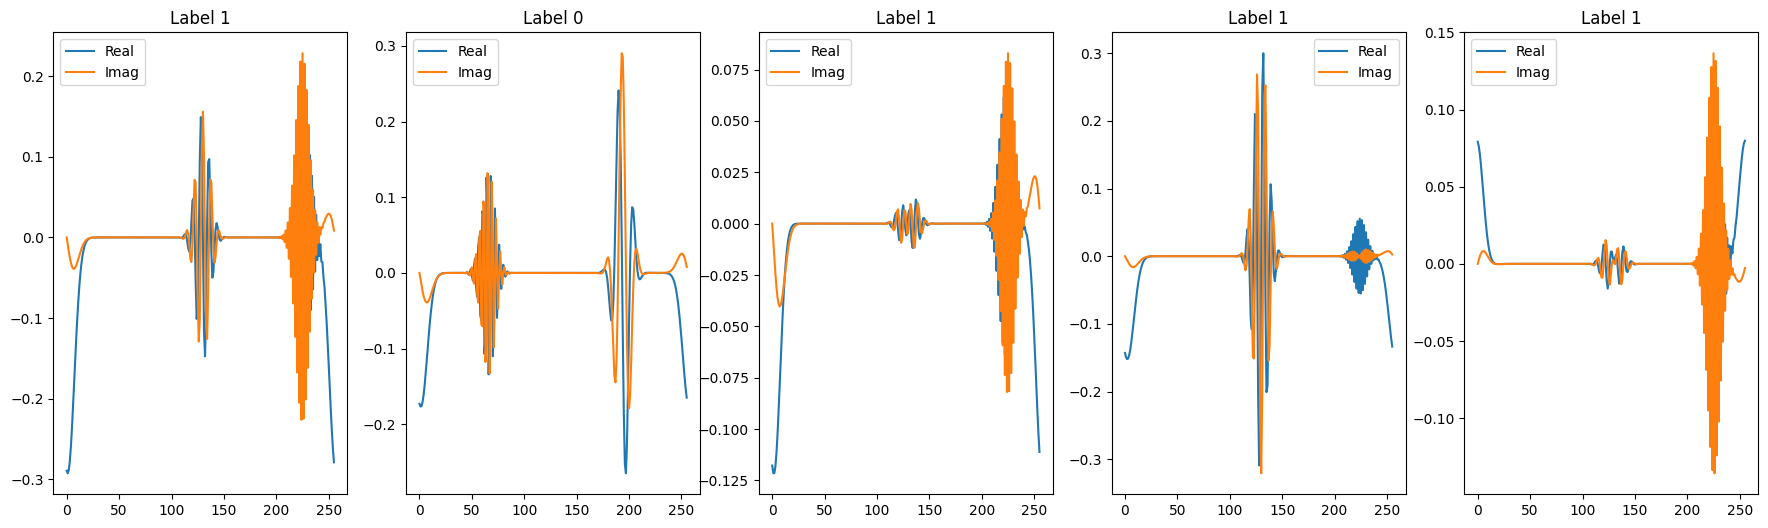

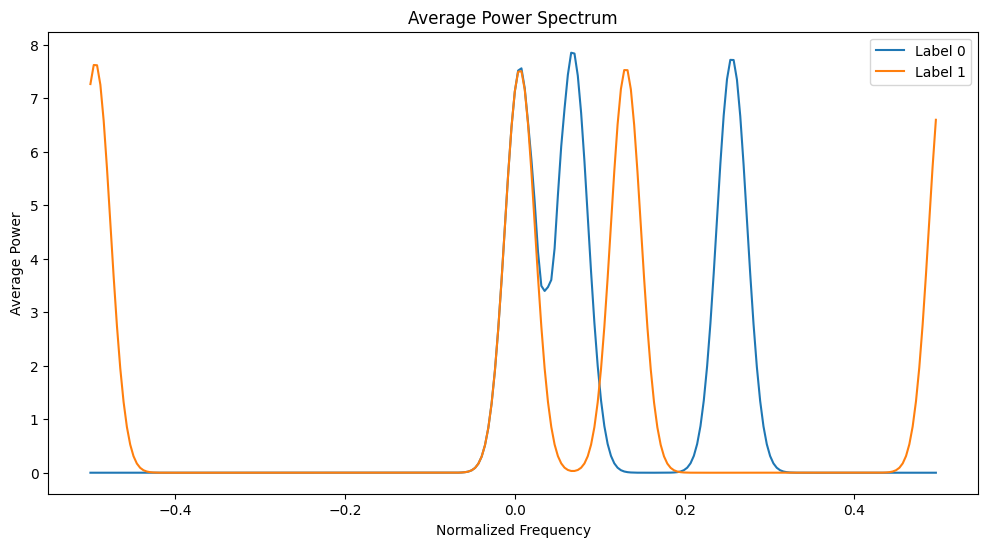

In [3]:
idxs = np.random.choice(range(len(X)), size=5)
fig, axs = plt.subplots(1, len(idxs), figsize=(22, 6))
for img_i, i in enumerate(idxs):
    axs[img_i].plot(X[i].real, label="Real")
    axs[img_i].plot(X[i].imag, label="Imag")
    axs[img_i].set_title(f"Label {y[i]}")
    axs[img_i].legend()

fft1 = np.fft.fftshift(
    np.fft.fft(df1.values, axis=1),
    axes=1
)

fft2 = np.fft.fftshift(
    np.fft.fft(df2.values, axis=1),
    axes=1
)

power1 = np.abs(fft1)**2
power2 = np.abs(fft2)**2

avg_power1 = power1.mean(axis=0)
avg_power2 = power2.mean(axis=0)

freqs = np.fft.fftshift(
    np.fft.fftfreq(df1.shape[1])
)

plt.figure(figsize=(12, 6))

plt.plot(freqs, avg_power1, label="Label 0")
plt.plot(freqs, avg_power2, label="Label 1")
plt.title("Average Power Spectrum")
plt.xlabel("Normalized Frequency")
plt.ylabel("Average Power")

plt.legend()

plt.show()

# Training on the clean data

In [4]:
import torch
import torch.nn as nn
from complexPyTorch.complexLayers import ComplexLinear, ComplexReLU

class MLPSignalClassifier(nn.Module):
    def __init__(self, input_size, hidden_dim, n_layers=1):
        super().__init__()
        self.layers_list = [ComplexLinear(input_size, hidden_dim)]
        for _ in range(n_layers):
            self.layers_list.append(ComplexLinear(hidden_dim, hidden_dim))
            self.layers_list.append(ComplexReLU())
        
        self.layers = nn.Sequential(*self.layers_list)
        self.classifier_head = nn.Linear(hidden_dim * 2, 1)

    def forward(self, x):
        x = self.layers(x)
        x = torch.cat([x.real, x.imag], dim=1)
        x = self.classifier_head(x)
        return x

In [5]:
from torch.utils.data import TensorDataset, Subset, DataLoader
from sklearn.model_selection import train_test_split

BATCH_SIZE = 64

X_t = torch.tensor(X, dtype=torch.complex64)
y_t = torch.tensor(y, dtype=torch.float)

dataset = TensorDataset(X_t, y_t.unsqueeze(-1))

# train_dataset, test_dataset = torch.utils.data.random_split(dataset, [0.8, 0.2])
idx = np.arange(len(X))

train_idx, test_idx = train_test_split(
    idx,
    test_size=0.2,
    stratify=y,
    random_state=42
)

train_dataset = Subset(dataset, train_idx)
test_dataset = Subset(dataset, test_idx)

train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

Epoch 01 | train loss=0.6514 | train acc=73.32% | val loss=0.5131 | val acc=99.61%
Epoch 02 | train loss=0.2581 | train acc=99.76% | val loss=0.0325 | val acc=100.00%
Epoch 03 | train loss=0.0119 | train acc=100.00% | val loss=0.0014 | val acc=100.00%
Epoch 04 | train loss=0.0013 | train acc=100.00% | val loss=0.0004 | val acc=100.00%
Epoch 05 | train loss=0.0004 | train acc=100.00% | val loss=0.0002 | val acc=100.00%
Epoch 06 | train loss=0.0003 | train acc=100.00% | val loss=0.0001 | val acc=100.00%
Epoch 07 | train loss=0.0002 | train acc=100.00% | val loss=0.0001 | val acc=100.00%
Epoch 08 | train loss=0.0002 | train acc=100.00% | val loss=0.0001 | val acc=100.00%
Epoch 09 | train loss=0.0001 | train acc=100.00% | val loss=0.0001 | val acc=100.00%
Epoch 10 | train loss=0.0001 | train acc=100.00% | val loss=0.0001 | val acc=100.00%


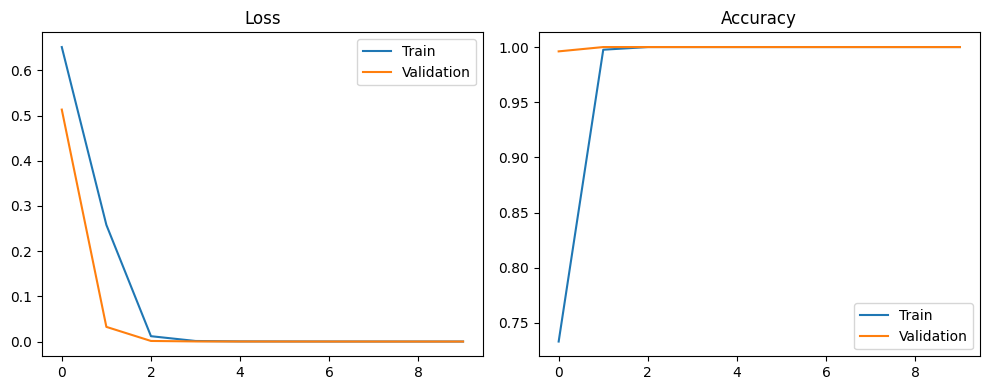

In [6]:
def binary_accuracy(preds, y, logits=True):
    if logits:
        rounded_preds = torch.round(torch.sigmoid(preds))
    else:
        rounded_preds = torch.round(preds)
    correct = (rounded_preds == y).float()
    accuracy = correct.sum() / len(y)
    return accuracy

N, T = X.shape

mlp_model = MLPSignalClassifier(T, T, n_layers=2)
optimizer = torch.optim.Adam(mlp_model.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()

def train_model(
    model,
    train_loader,
    test_loader,
    optimizer,
    epochs=10,
    device="cpu"
):

    model.to(device)

    criterion = nn.BCEWithLogitsLoss()

    train_losses = []
    train_accuracies = []

    val_losses = []
    val_accuracies = []

    for epoch in range(epochs):
        # training
        model.train()

        epoch_loss = 0.0
        epoch_acc = 0.0

        for inputs, labels in train_loader:
            inputs = inputs.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            acc = binary_accuracy(outputs, labels)

            epoch_loss += loss.item()
            epoch_acc += acc.item()

        epoch_loss /= len(train_loader)
        epoch_acc /= len(train_loader)

        train_losses.append(epoch_loss)
        train_accuracies.append(epoch_acc)

        # validation
        model.eval()

        val_loss = 0.0
        val_acc = 0.0

        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs = inputs.to(device)

                outputs = model(inputs)

                loss = criterion(outputs, labels)

                acc = binary_accuracy(outputs, labels)

                val_loss += loss.item()
                val_acc += acc.item()

        val_loss /= len(test_loader)
        val_acc /= len(test_loader)

        val_losses.append(val_loss)
        val_accuracies.append(val_acc)

        print(
            f"Epoch {epoch+1:02d} | "
            f"train loss={epoch_loss:.4f} | "
            f"train acc={epoch_acc*100:.2f}% | "
            f"val loss={val_loss:.4f} | "
            f"val acc={val_acc*100:.2f}%"
        )

    # plotting
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.plot(train_losses, label="Train")
    plt.plot(val_losses, label="Validation")
    plt.title("Loss")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(train_accuracies, label="Train")
    plt.plot(val_accuracies, label="Validation")
    plt.title("Accuracy")
    plt.legend()

    plt.tight_layout()
    plt.show()

    return {
        "train_losses": train_losses,
        "train_accuracies": train_accuracies,
        "val_losses": val_losses,
        "val_accuracies": val_accuracies,
    }

EPOCHS = 10

history = train_model(
    mlp_model,
    train_dataloader,
    test_dataloader,
    optimizer,
    epochs=EPOCHS,
)

As we can see the model can easily learn to classify the data with 100% accuracy within a few episodes. The task seems to be almost trivial to learn.

# Noisy data

We plot the noisy data and its spectrum in the form of a power spectrum, which is just the magnitude spectrum squared. For single samples the power spectrum is very noisy, which is why we plot the averaged power spectrum over the whole dataset.

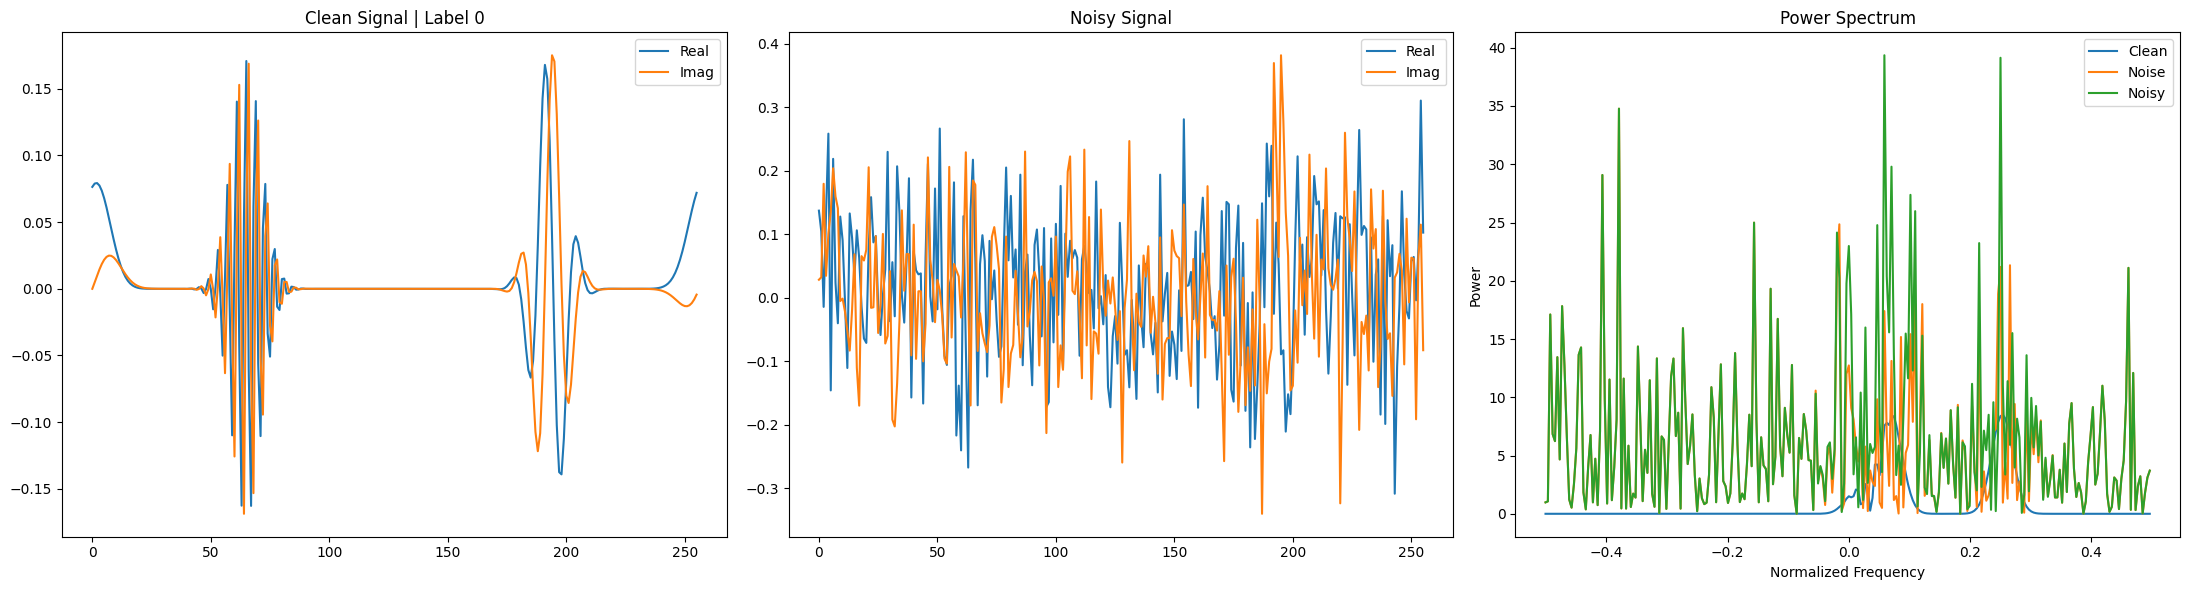

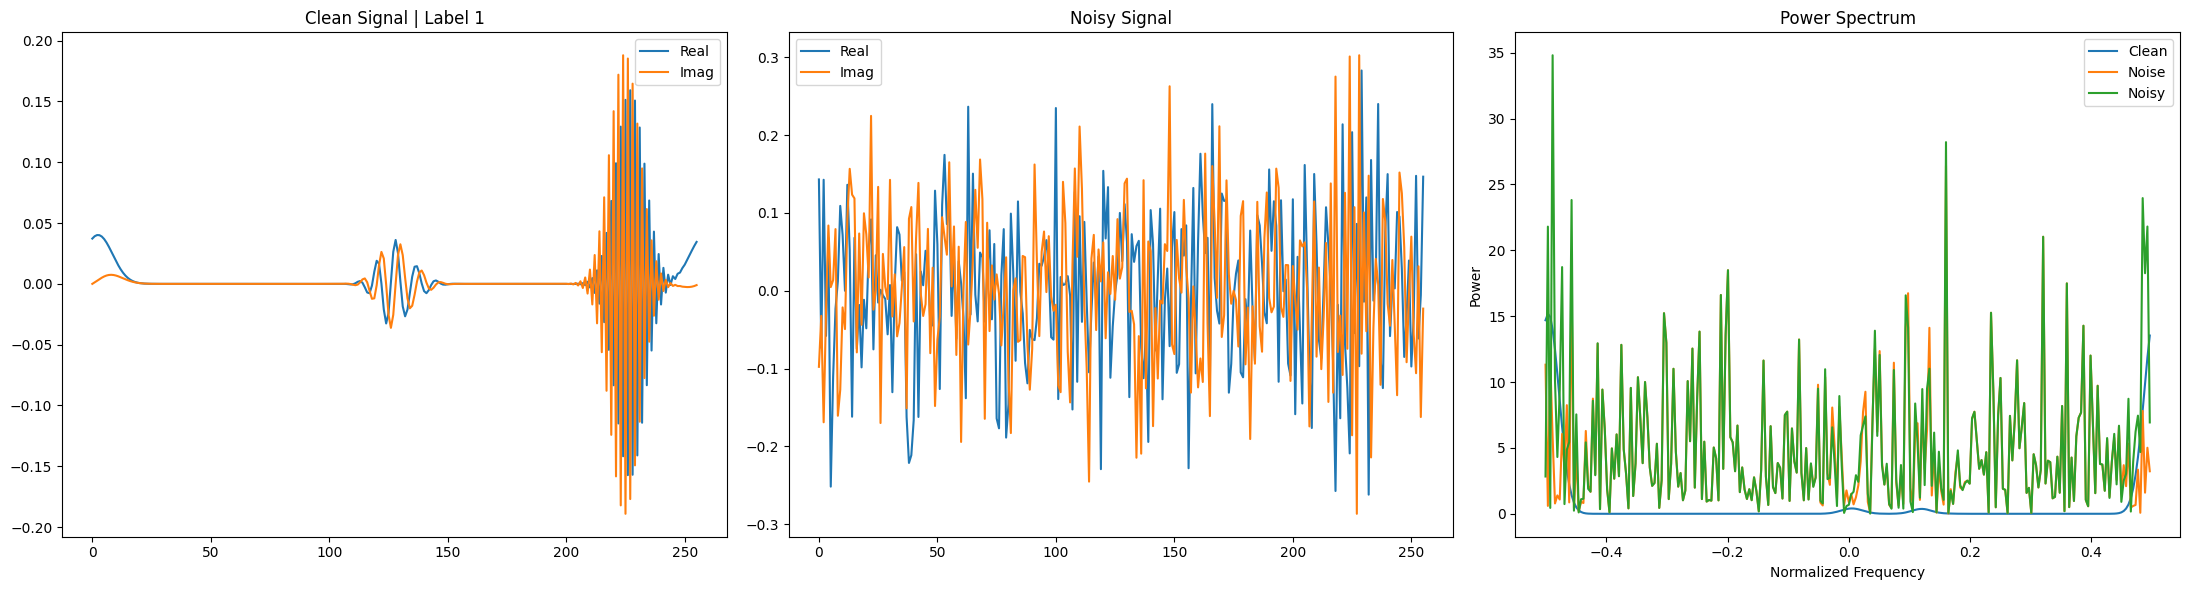

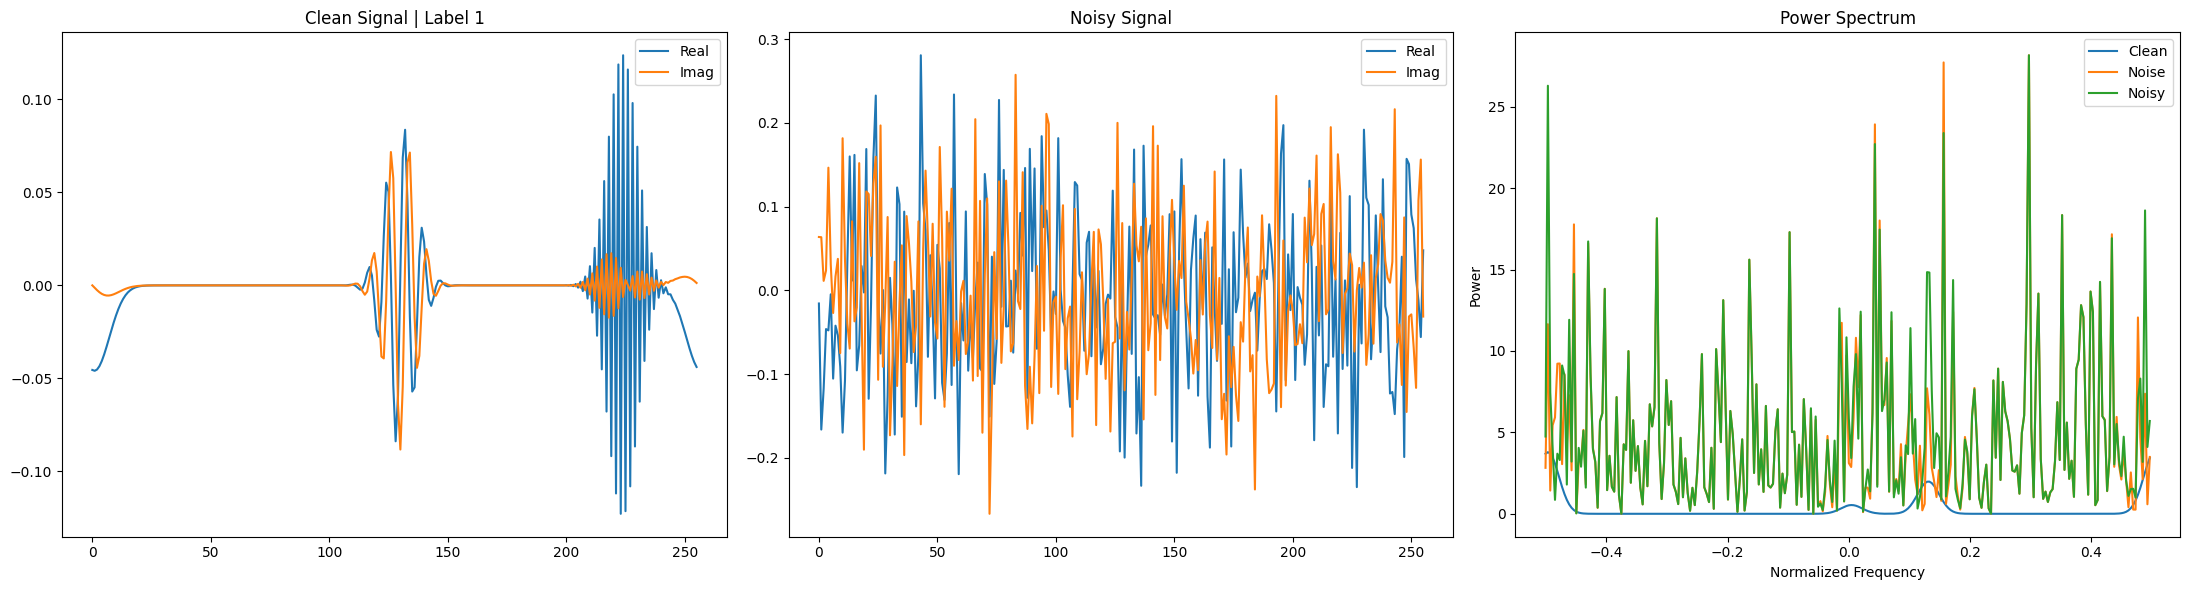

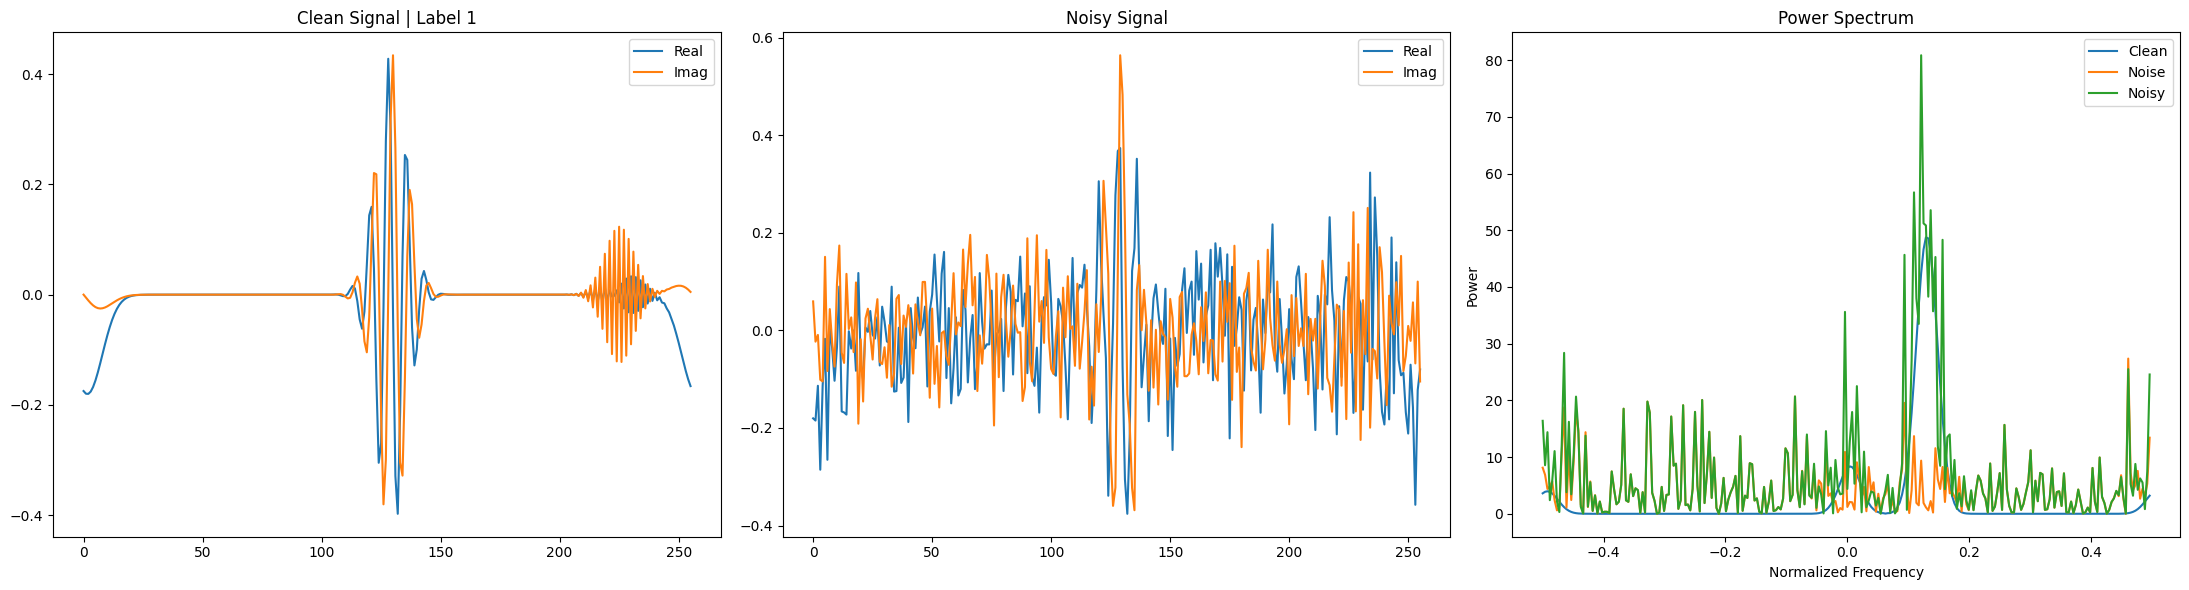

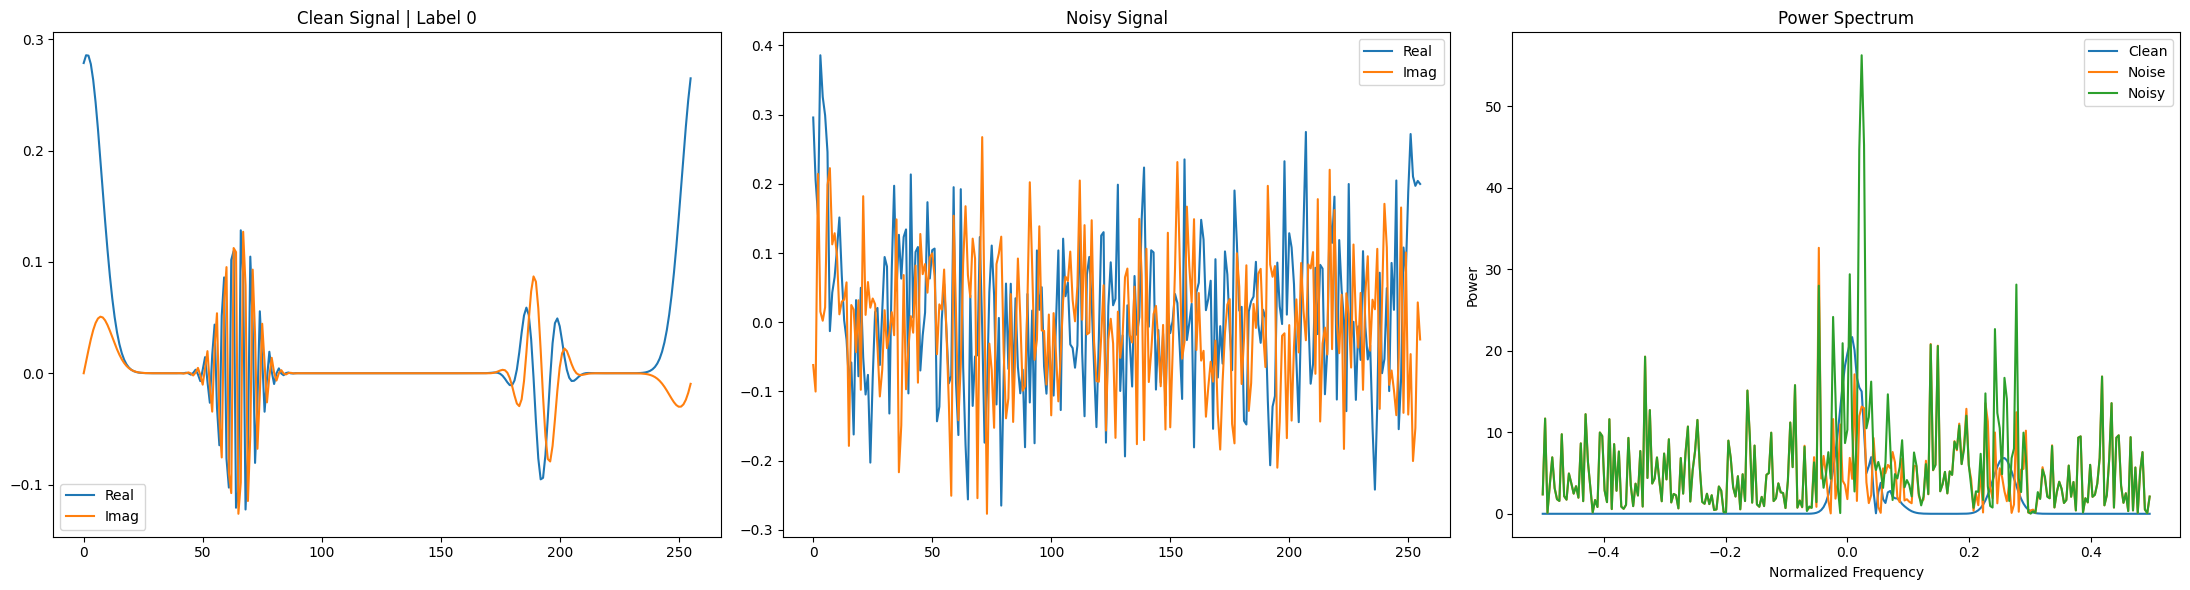

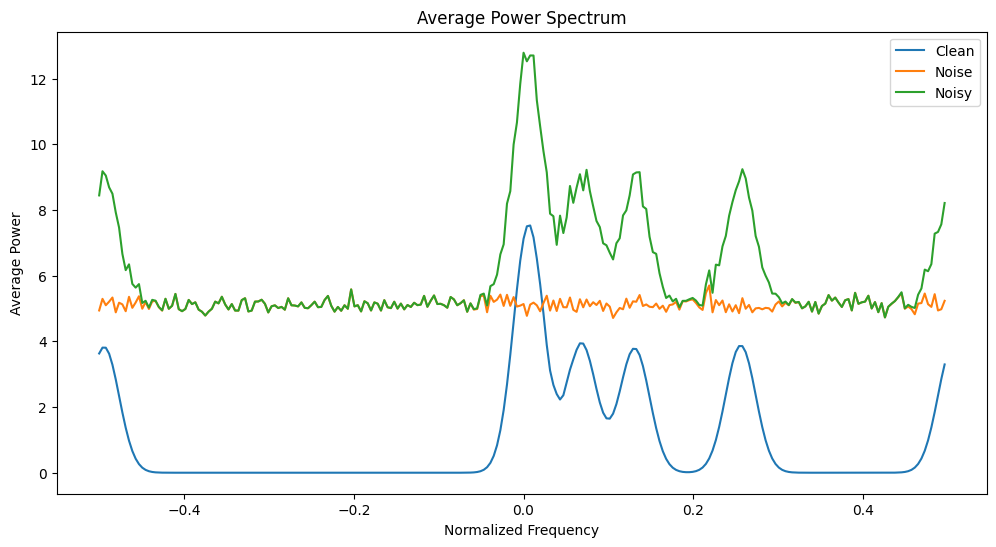

In [7]:
sigma = 0.1

noise_real = np.random.normal(
    loc=0.0,
    scale=sigma,
    size=X.shape
)

noise_imag = np.random.normal(
    loc=0.0,
    scale=sigma,
    size=X.shape
)

noise = noise_real + 1j * noise_imag

X_n = X + noise

idxs = np.random.choice(range(len(X_n)), size=5)

for i in idxs:
    fig, ax = plt.subplots(1, 3, figsize=(22, 6))

    # Clean signal
    ax[0].plot(X[i].real, label="Real")
    ax[0].plot(X[i].imag, label="Imag")

    ax[0].set_title(f"Clean Signal | Label {y[i]}")
    ax[0].legend()

    # Noisy signal
    ax[1].plot(X_n[i].real, label="Real")
    ax[1].plot(X_n[i].imag, label="Imag")

    ax[1].set_title("Noisy Signal")
    ax[1].legend()

    # Power spectra
    clean_fft = np.fft.fftshift(np.fft.fft(X[i]))
    noise_fft = np.fft.fftshift(np.fft.fft(noise[i]))
    noisy_fft = np.fft.fftshift(np.fft.fft(X_n[i]))

    clean_power = np.abs(clean_fft)**2
    noise_power = np.abs(noise_fft)**2
    noisy_power = np.abs(noisy_fft)**2

    freqs = np.fft.fftshift(
        np.fft.fftfreq(len(X[i]))
    )

    ax[2].plot(freqs, clean_power, label="Clean")
    ax[2].plot(freqs, noise_power, label="Noise")
    ax[2].plot(freqs, noisy_power, label="Noisy")

    ax[2].set_title("Power Spectrum")
    ax[2].set_xlabel("Normalized Frequency")
    ax[2].set_ylabel("Power")

    ax[2].legend()

    plt.tight_layout()
    plt.show()

# Averaged power spectrum
clean_fft = np.fft.fftshift(
    np.fft.fft(X, axis=1),
    axes=1
)

noise_fft = np.fft.fftshift(
    np.fft.fft(noise, axis=1),
    axes=1
)

noisy_fft = np.fft.fftshift(
    np.fft.fft(X_n, axis=1),
    axes=1
)

# Power spectra
clean_power = np.abs(clean_fft)**2
noise_power = np.abs(noise_fft)**2
noisy_power = np.abs(noisy_fft)**2

# Average over all signals
avg_clean_power = clean_power.mean(axis=0)
avg_noise_power = noise_power.mean(axis=0)
avg_noisy_power = noisy_power.mean(axis=0)

freqs = np.fft.fftshift(
    np.fft.fftfreq(X.shape[1])
)

plt.figure(figsize=(12, 6))

plt.plot(freqs, avg_clean_power, label="Clean")
plt.plot(freqs, avg_noise_power, label="Noise")
plt.plot(freqs, avg_noisy_power, label="Noisy")

plt.title("Average Power Spectrum")
plt.xlabel("Normalized Frequency")
plt.ylabel("Average Power")

plt.legend()

plt.show()

Epoch 01 | train loss=0.6955 | train acc=48.99% | val loss=0.6893 | val acc=59.13%
Epoch 02 | train loss=0.5946 | train acc=75.39% | val loss=0.4595 | val acc=79.39%
Epoch 03 | train loss=0.1408 | train acc=95.40% | val loss=0.5485 | val acc=85.22%
Epoch 04 | train loss=0.0503 | train acc=98.08% | val loss=0.3096 | val acc=92.61%
Epoch 05 | train loss=0.0139 | train acc=99.64% | val loss=0.1809 | val acc=94.92%
Epoch 06 | train loss=0.0021 | train acc=100.00% | val loss=0.2173 | val acc=93.75%
Epoch 07 | train loss=0.0011 | train acc=100.00% | val loss=0.2259 | val acc=93.75%
Epoch 08 | train loss=0.0003 | train acc=100.00% | val loss=0.2370 | val acc=94.14%
Epoch 09 | train loss=0.0002 | train acc=100.00% | val loss=0.2524 | val acc=93.75%
Epoch 10 | train loss=0.0001 | train acc=100.00% | val loss=0.2685 | val acc=93.75%
Epoch 11 | train loss=0.0001 | train acc=100.00% | val loss=0.2821 | val acc=93.75%
Epoch 12 | train loss=0.0001 | train acc=100.00% | val loss=0.2914 | val acc=93.7

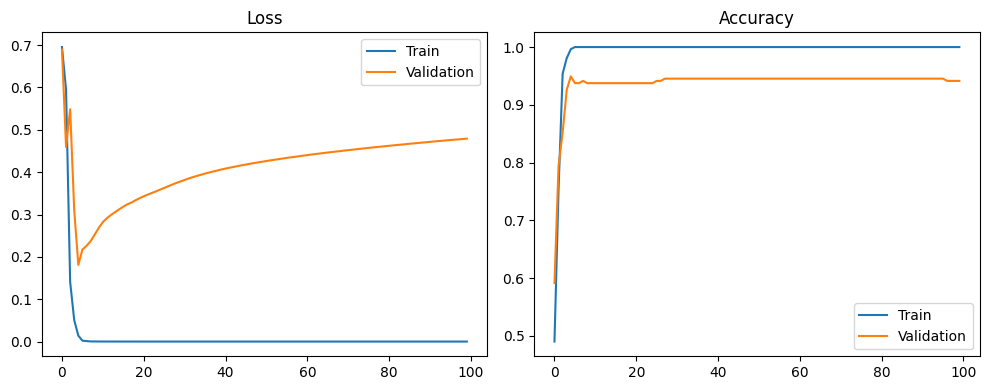

In [8]:
X_n_t = torch.tensor(X_n, dtype=torch.complex64)

idx = np.arange(len(X_n))

train_idx, test_idx = train_test_split(
    idx,
    test_size=0.2,
    stratify=y,
    random_state=42
)

noisy_dataset = TensorDataset(X_n_t, y_t.unsqueeze(-1))

train_noisy_dataset = Subset(noisy_dataset, train_idx)
test_noisy_dataset = Subset(noisy_dataset, test_idx)

train_noisy_dataloader = DataLoader(train_noisy_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_noisy_dataloader = DataLoader(test_noisy_dataset, batch_size=BATCH_SIZE, shuffle=False)

mlp_model = MLPSignalClassifier(T, T, n_layers=4) # 4, 10
optimizer = torch.optim.Adam(mlp_model.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()

EPOCHS = 100

history = train_model(
    mlp_model,
    train_noisy_dataloader,
    test_noisy_dataloader,
    optimizer,
    epochs=EPOCHS,
)

As we expected the classification performance decreases when we train on the noisy data.

# Classical data augmentation

TODO: $2^{8}=256$ might be too large to yield an improvement for Harmoniq

In [9]:
from torch.utils.data import Dataset

n = int(np.log2(T))
d = 2**n


def augment_dataset(F, shift, mod):
    """
    x: (T,) or (N,T)
    shift: time shift
    mod: frequency shift
    """

    if F.ndim == 1:
        T = F.shape[0]
        t = np.arange(T)

        shifted = np.roll(F, shift)
        modulated = np.exp(2j * np.pi * mod * t / T) * shifted

        return modulated

    else:
        # batch version
        N, T = F.shape
        t = np.arange(T)

        shifted = np.roll(F, shift, axis=1)
        modulated = np.exp(2j * np.pi * mod * t / T)[None, :] * shifted

        return modulated

def build_wh_augmentation(F, r):
    augmented = []

    for x in range(-r, r + 1):
        for z in range(-r, r + 1):
            X_xz = augment_dataset(F, x, z)

            augmented.append(X_xz)

    return np.stack(augmented, axis=0)

class WHDataset(Dataset):
    def __init__(self, X, y, r=2, mode="deterministic"):
        self.X = X
        self.y = y
        self.r = r
        self.mode = mode

        self.omega = [(x, z)
                      for x in range(-r, r+1)
                      for z in range(-r, r+1)]

    def __len__(self):
        if self.mode == "deterministic":
            return len(self.X) * len(self.omega)
        else:
            return len(self.X)

    def __getitem__(self, idx):
        if self.mode == "deterministic":

            sample_idx = idx // len(self.omega)
            transform_idx = idx % len(self.omega)

            shift, mod = self.omega[transform_idx]

            x = self.X[sample_idx]
            y = self.y[sample_idx]

            x_aug = augment_dataset(x, shift, mod)

        elif self.mode == "random":

            x = self.X[idx]
            y = self.y[idx]

            shift = np.random.randint(-self.r, self.r + 1)
            mod = np.random.randint(-self.r, self.r + 1)

            x_aug = augment_dataset(x, shift, mod)

        else:

            x = self.X[idx]
            y = self.y[idx]

            x_aug = x

        return (
            torch.tensor(x_aug, dtype=torch.complex64),
            torch.tensor(y, dtype=torch.float32).unsqueeze(0)
        )
    

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X_n,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

r = 2

train_aug_dataset = WHDataset(X_train, y_train, r=r, mode="deterministic")
test_aug_dataset = TensorDataset(torch.tensor(X_test, dtype=torch.complex64), torch.tensor(y_test, dtype=torch.float32).unsqueeze(-1))

input, label = train_aug_dataset[0]
input.shape, label.shape

(torch.Size([256]), torch.Size([1]))

We perform our train/test split before augmentation, s.t. the test set is unaugmented

# Training on augmented data

Epoch 01 | train loss=0.1362 | train acc=94.14% | val loss=0.0458 | val acc=97.27%
Epoch 02 | train loss=0.0213 | train acc=99.28% | val loss=0.0489 | val acc=98.83%
Epoch 03 | train loss=0.0109 | train acc=99.58% | val loss=0.0448 | val acc=98.05%
Epoch 04 | train loss=0.0049 | train acc=99.84% | val loss=0.0381 | val acc=98.05%
Epoch 05 | train loss=0.0021 | train acc=99.96% | val loss=0.0477 | val acc=98.05%
Epoch 06 | train loss=0.0012 | train acc=99.97% | val loss=0.0485 | val acc=98.05%
Epoch 07 | train loss=0.0005 | train acc=100.00% | val loss=0.0461 | val acc=98.05%
Epoch 08 | train loss=0.0001 | train acc=100.00% | val loss=0.0459 | val acc=98.05%
Epoch 09 | train loss=0.0001 | train acc=100.00% | val loss=0.0462 | val acc=98.05%
Epoch 10 | train loss=0.0001 | train acc=100.00% | val loss=0.0469 | val acc=98.05%
Epoch 11 | train loss=0.0000 | train acc=100.00% | val loss=0.0475 | val acc=98.05%
Epoch 12 | train loss=0.0000 | train acc=100.00% | val loss=0.0485 | val acc=98.05

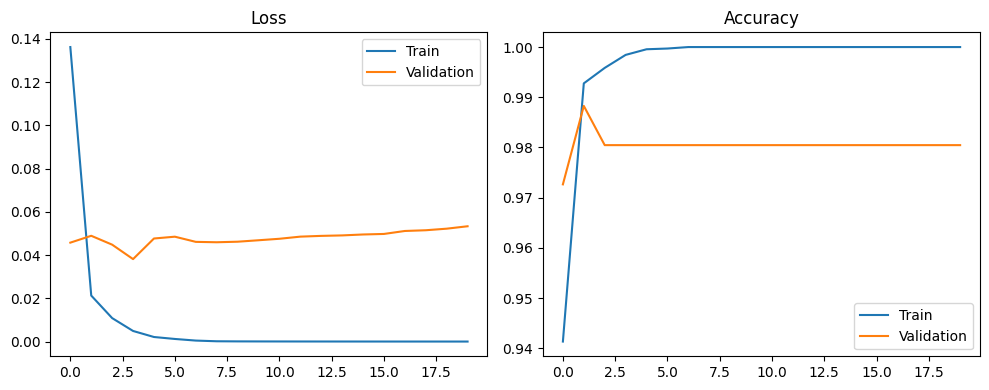

In [11]:
train_aug_loader = DataLoader(
    train_aug_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_aug_loader = DataLoader(
    test_aug_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False # otherwhise evaluation noisy and inconsistent
)

mlp_model = MLPSignalClassifier(T, T, n_layers=1)
optimizer = torch.optim.Adam(mlp_model.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()

EPOCHS = 20

history = train_model(
    mlp_model,
    train_aug_loader,
    test_aug_loader,
    optimizer,
    epochs=EPOCHS,
)

In [12]:
len(train_aug_dataset), len(train_noisy_dataset)


(20475, 819)

# Randomly sampling over a very broad $\Omega$

Epoch 01 | train loss=0.6920 | train acc=50.65% | val loss=0.6846 | val acc=56.79%
Epoch 02 | train loss=0.6708 | train acc=62.10% | val loss=0.6477 | val acc=74.67%
Epoch 03 | train loss=0.5876 | train acc=86.00% | val loss=0.5038 | val acc=91.83%
Epoch 04 | train loss=0.3883 | train acc=94.53% | val loss=0.2556 | val acc=94.95%
Epoch 05 | train loss=0.1887 | train acc=96.54% | val loss=0.1330 | val acc=95.34%
Epoch 06 | train loss=0.0937 | train acc=97.96% | val loss=0.1007 | val acc=96.12%
Epoch 07 | train loss=0.0666 | train acc=98.44% | val loss=0.0805 | val acc=95.73%
Epoch 08 | train loss=0.0489 | train acc=98.44% | val loss=0.0786 | val acc=95.34%
Epoch 09 | train loss=0.0482 | train acc=98.65% | val loss=0.0679 | val acc=95.73%
Epoch 10 | train loss=0.0356 | train acc=98.80% | val loss=0.0542 | val acc=98.05%
Epoch 11 | train loss=0.0372 | train acc=99.04% | val loss=0.0532 | val acc=97.66%
Epoch 12 | train loss=0.0335 | train acc=98.74% | val loss=0.0634 | val acc=96.91%
Epoc

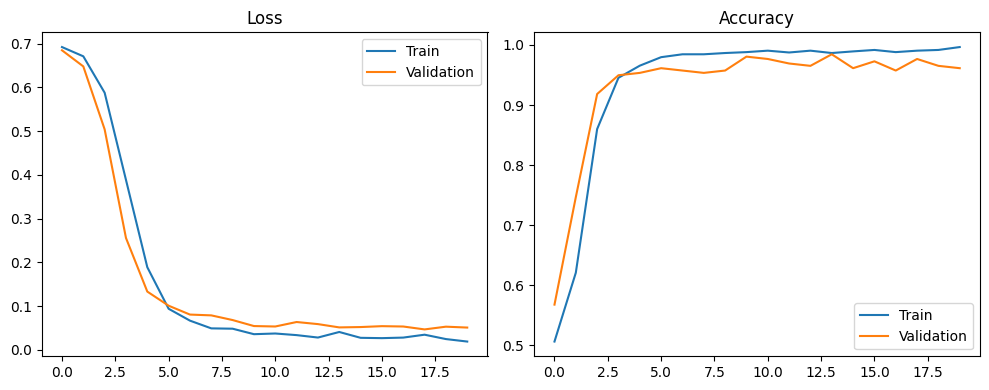

In [13]:
r = 2

train_aug_dataset_broad = WHDataset(X_train, y_train, r=r, mode="random")

train_aug_loader_broad = DataLoader(
    train_aug_dataset_broad,
    batch_size=BATCH_SIZE,
    shuffle=True
)


mlp_model = MLPSignalClassifier(T, T, n_layers=1)
optimizer = torch.optim.Adam(mlp_model.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()

EPOCHS = 20

history = train_model(
    mlp_model,
    train_aug_loader_broad,
    test_aug_loader,
    optimizer,
    epochs=EPOCHS,
)

Epoch 01 | train loss=0.6950 | train acc=47.67% | val loss=0.6869 | val acc=59.89%
Epoch 02 | train loss=0.6944 | train acc=49.75% | val loss=0.6865 | val acc=55.98%
Epoch 03 | train loss=0.6946 | train acc=49.87% | val loss=0.6845 | val acc=57.54%
Epoch 04 | train loss=0.6916 | train acc=52.42% | val loss=0.6815 | val acc=60.31%
Epoch 05 | train loss=0.6907 | train acc=52.30% | val loss=0.6783 | val acc=68.03%
Epoch 06 | train loss=0.6866 | train acc=56.27% | val loss=0.6727 | val acc=68.84%
Epoch 07 | train loss=0.6786 | train acc=62.85% | val loss=0.6591 | val acc=70.43%
Epoch 08 | train loss=0.6677 | train acc=64.60% | val loss=0.6345 | val acc=78.16%
Epoch 09 | train loss=0.6590 | train acc=64.95% | val loss=0.5996 | val acc=82.45%
Epoch 10 | train loss=0.6366 | train acc=70.31% | val loss=0.5612 | val acc=87.11%
Epoch 11 | train loss=0.5859 | train acc=77.91% | val loss=0.5055 | val acc=82.09%
Epoch 12 | train loss=0.5291 | train acc=79.41% | val loss=0.4170 | val acc=88.28%
Epoc

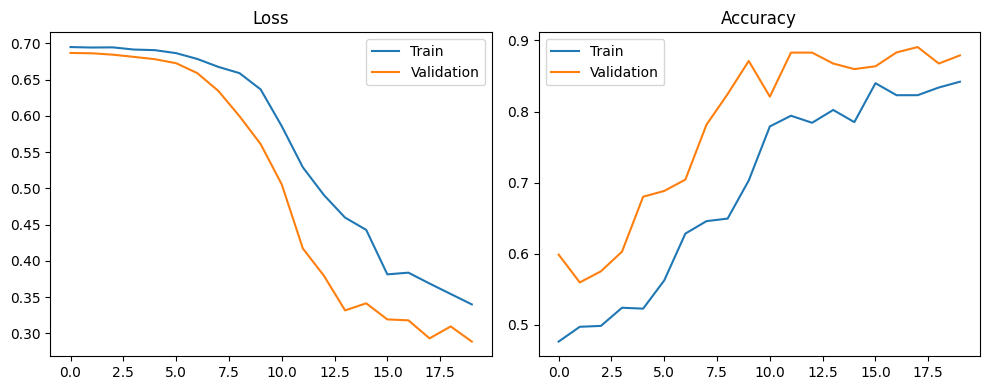

In [14]:
r = 20

train_aug_dataset_broad = WHDataset(X_train, y_train, r=r, mode="random")

train_aug_loader_broad = DataLoader(
    train_aug_dataset_broad,
    batch_size=BATCH_SIZE,
    shuffle=True
)


mlp_model = MLPSignalClassifier(T, T, n_layers=1)
optimizer = torch.optim.Adam(mlp_model.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()

EPOCHS = 20

history = train_model(
    mlp_model,
    train_aug_loader_broad,
    test_aug_loader,
    optimizer,
    epochs=EPOCHS,
)

# Training a 1D-CNN

In [15]:
from complexPyTorch.complexLayers import apply_complex
from torch.nn import Conv1d
from torch.nn.functional import avg_pool1d


class ComplexConv1d(nn.Module):
    def __init__(self,in_channels, out_channels, kernel_size=3, stride=1, padding = 0,
                 dilation=1, groups=1, bias=True):
        super(ComplexConv1d, self).__init__()
        self.conv_r = Conv1d(in_channels, out_channels, kernel_size, stride, padding, dilation, groups, bias)
        self.conv_i = Conv1d(in_channels, out_channels, kernel_size, stride, padding, dilation, groups, bias)
        
    def forward(self,input):    
        return apply_complex(self.conv_r, self.conv_i, input)

def complex_avg_pool1d(input, *args, **kwargs):
    '''
    Perform complex average pooling.
    '''    
    absolute_value_real = avg_pool1d(input.real, *args, **kwargs)
    absolute_value_imag =  avg_pool1d(input.imag, *args, **kwargs)    
    
    return absolute_value_real.type(torch.complex64)+1j*absolute_value_imag.type(torch.complex64)

class ComplexAvgPool1d(nn.Module):

    def __init__(self,kernel_size, stride= None, padding = 0, ceil_mode = False):
        super(ComplexAvgPool1d,self).__init__()
        self.kernel_size = kernel_size
        self.stride = stride
        self.padding = padding
        self.ceil_mode = ceil_mode

    def forward(self,input):
        return complex_avg_pool1d(input,kernel_size = self.kernel_size,
                                stride = self.stride, padding = self.padding,
                                ceil_mode = self.ceil_mode)
    
class CNNSignalClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            ComplexConv1d(
                in_channels=1,
                out_channels=8,
                kernel_size=5,
                padding=2,
            ),
            ComplexReLU(),
            ComplexAvgPool1d(2),

            ComplexConv1d(
                in_channels=8,
                out_channels=16,
                kernel_size=5,
                padding=2,
            ),
            ComplexReLU(),
            ComplexAvgPool1d(2),
        )
        self.classifier = nn.Sequential(
            nn.Linear(16 * 2, 32), # real + imaginary part
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        x = x.unsqueeze(1)
        x = self.net(x)
        x = x.mean(dim=-1)
        x = torch.cat([x.real, x.imag], dim=1)
        x = self.classifier(x)
        return x

Epoch 01 | train loss=0.6942 | train acc=49.41% | val loss=0.6930 | val acc=50.57%
Epoch 02 | train loss=0.6931 | train acc=55.18% | val loss=0.6929 | val acc=49.43%
Epoch 03 | train loss=0.6930 | train acc=60.14% | val loss=0.6928 | val acc=50.57%
Epoch 04 | train loss=0.6933 | train acc=48.30% | val loss=0.6927 | val acc=49.43%
Epoch 05 | train loss=0.6925 | train acc=54.56% | val loss=0.6923 | val acc=96.09%
Epoch 06 | train loss=0.6922 | train acc=53.23% | val loss=0.6919 | val acc=50.57%
Epoch 07 | train loss=0.6917 | train acc=71.84% | val loss=0.6913 | val acc=98.05%
Epoch 08 | train loss=0.6911 | train acc=54.04% | val loss=0.6903 | val acc=65.78%
Epoch 09 | train loss=0.6901 | train acc=63.98% | val loss=0.6890 | val acc=56.82%
Epoch 10 | train loss=0.6883 | train acc=58.92% | val loss=0.6869 | val acc=66.56%
Epoch 11 | train loss=0.6858 | train acc=63.39% | val loss=0.6834 | val acc=68.48%
Epoch 12 | train loss=0.6812 | train acc=68.15% | val loss=0.6777 | val acc=83.65%
Epoc

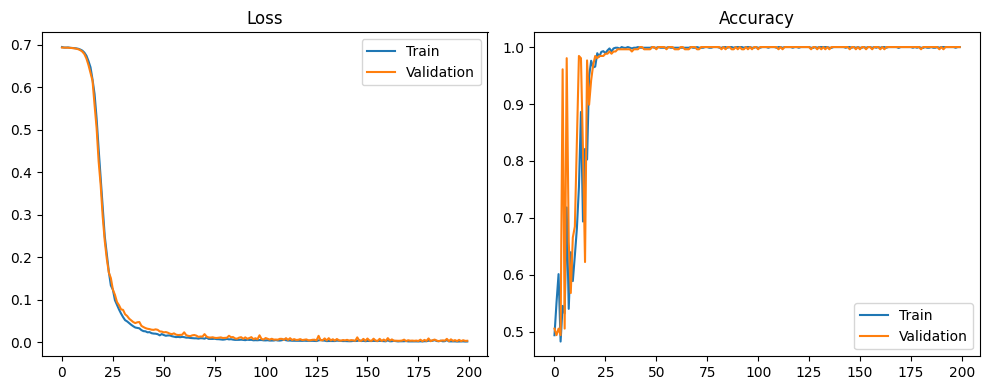

In [16]:
cnn_model = CNNSignalClassifier()
optimizer = torch.optim.Adam(cnn_model.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()

EPOCHS = 200

history = train_model(
    cnn_model,
    train_dataloader,
    test_dataloader,
    optimizer,
    epochs=EPOCHS,
)

Epoch 01 | train loss=0.6942 | train acc=50.17% | val loss=0.6931 | val acc=50.57%
Epoch 02 | train loss=0.6937 | train acc=45.68% | val loss=0.6932 | val acc=49.43%
Epoch 03 | train loss=0.6933 | train acc=49.86% | val loss=0.6932 | val acc=40.53%
Epoch 04 | train loss=0.6937 | train acc=50.58% | val loss=0.6931 | val acc=50.57%
Epoch 05 | train loss=0.6932 | train acc=50.08% | val loss=0.6931 | val acc=50.57%
Epoch 06 | train loss=0.6931 | train acc=50.14% | val loss=0.6931 | val acc=50.57%
Epoch 07 | train loss=0.6933 | train acc=50.04% | val loss=0.6930 | val acc=50.57%
Epoch 08 | train loss=0.6931 | train acc=49.18% | val loss=0.6930 | val acc=49.43%
Epoch 09 | train loss=0.6931 | train acc=53.95% | val loss=0.6930 | val acc=49.43%
Epoch 10 | train loss=0.6930 | train acc=49.68% | val loss=0.6928 | val acc=50.57%
Epoch 11 | train loss=0.6931 | train acc=49.92% | val loss=0.6927 | val acc=50.57%
Epoch 12 | train loss=0.6929 | train acc=48.18% | val loss=0.6928 | val acc=49.43%
Epoc

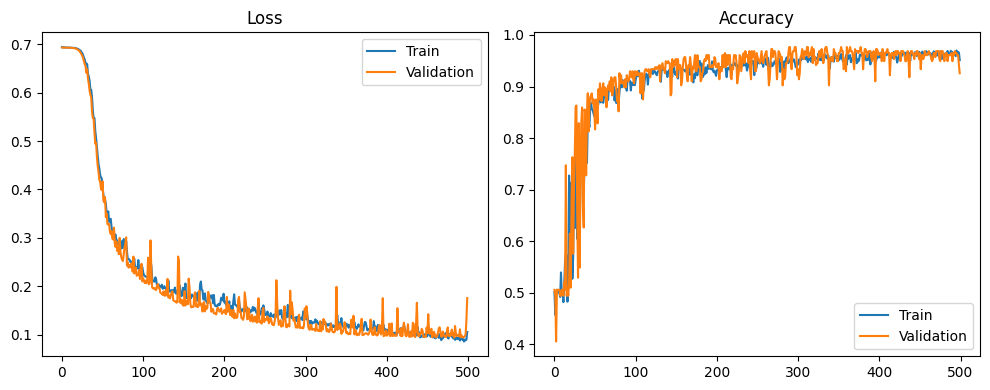

In [17]:
cnn_model = CNNSignalClassifier()
optimizer = torch.optim.Adam(cnn_model.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()

EPOCHS = 500

history = train_model(
    cnn_model,
    train_noisy_dataloader,
    test_noisy_dataloader,
    optimizer,
    epochs=EPOCHS,
)

Epoch 01 | train loss=0.6894 | train acc=53.29% | val loss=0.6697 | val acc=54.51%
Epoch 02 | train loss=0.5514 | train acc=74.20% | val loss=0.3646 | val acc=87.14%
Epoch 03 | train loss=0.3596 | train acc=84.76% | val loss=0.2734 | val acc=87.92%
Epoch 04 | train loss=0.2824 | train acc=88.16% | val loss=0.1982 | val acc=92.97%
Epoch 05 | train loss=0.2370 | train acc=90.20% | val loss=0.1677 | val acc=92.97%
Epoch 06 | train loss=0.2051 | train acc=91.64% | val loss=0.1443 | val acc=96.09%
Epoch 07 | train loss=0.1896 | train acc=92.28% | val loss=0.1616 | val acc=90.66%
Epoch 08 | train loss=0.1742 | train acc=93.11% | val loss=0.1389 | val acc=96.48%
Epoch 09 | train loss=0.1633 | train acc=93.40% | val loss=0.1112 | val acc=95.31%
Epoch 10 | train loss=0.1566 | train acc=93.53% | val loss=0.1416 | val acc=92.22%
Epoch 11 | train loss=0.1435 | train acc=94.30% | val loss=0.0967 | val acc=97.66%
Epoch 12 | train loss=0.1411 | train acc=94.39% | val loss=0.0909 | val acc=97.66%
Epoc

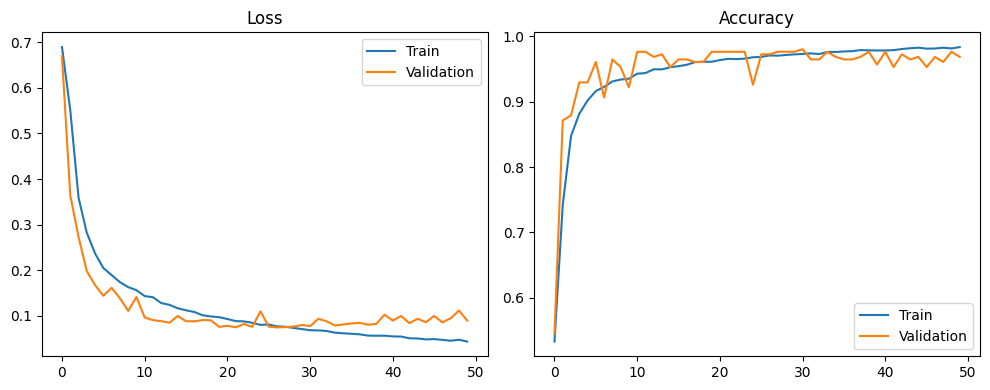

In [18]:
cnn_model = CNNSignalClassifier()
optimizer = torch.optim.Adam(cnn_model.parameters(), lr=1e-3)
criterion = nn.BCEWithLogitsLoss()

EPOCHS = 50

history = train_model(
    cnn_model,
    train_aug_loader,
    test_aug_loader,
    optimizer,
    epochs=EPOCHS,
)

In [19]:
print(np.bincount(y_train.astype(int)))
print(np.bincount(y_test.astype(int)))

[409 410]
[103 102]


# TODOs
- Figure out the classical case
    - Different sample size regimes
    - Different $|\Omega |$
    - Different $\sigma$
- Summarize findings
- read about Quantum NNs
    - can we train directly on $\rho$?
- implement quantum NNs

# Plots

## Acc vs sample size

In [ ]:
import matplotlib.cm as cm

class EarlyStopping:
    def __init__(self, patience=20, min_delta=1e-4):
        self.patience = patience
        self.min_delta = min_delta

        self.best_loss = np.inf
        self.counter = 0

    def step(self, val_loss):

        improved = val_loss < (self.best_loss - self.min_delta)

        if improved:
            self.best_loss = val_loss
            self.counter = 0
            return False

        self.counter += 1

        return self.counter >= self.patience
    
def train_model(
    model,
    train_loader,
    test_loader,
    optimizer,
    max_epochs=200,
    device="cpu",
    do_early_stopping=True,
    patience=20,
    min_delta=1e-4,
):

    model.to(device)

    criterion = nn.BCEWithLogitsLoss()

    early_stopper = EarlyStopping(
        patience=patience,
        min_delta=min_delta
    )

    train_losses = []
    val_losses = []

    train_accs = []
    val_accs = []

    best_val_acc = 0.0

    for epoch in range(max_epochs):

        # =========================
        # TRAIN
        # =========================

        model.train()

        epoch_loss = 0.0
        epoch_acc = 0.0

        for inputs, labels in train_loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            acc = binary_accuracy(outputs, labels)

            epoch_loss += loss.item()
            epoch_acc += acc.item()

        epoch_loss /= len(train_loader)
        epoch_acc /= len(train_loader)

        train_losses.append(epoch_loss)
        train_accs.append(epoch_acc)

        # =========================
        # VALIDATION
        # =========================

        model.eval()

        val_loss = 0.0
        val_acc = 0.0

        with torch.no_grad():

            for inputs, labels in test_loader:

                inputs = inputs.to(device)
                labels = labels.to(device)

                outputs = model(inputs)

                loss = criterion(outputs, labels)

                acc = binary_accuracy(outputs, labels)

                val_loss += loss.item()
                val_acc += acc.item()

        val_loss /= len(test_loader)
        val_acc /= len(test_loader)

        val_losses.append(val_loss)
        val_accs.append(val_acc)

        best_val_acc = max(best_val_acc, val_acc)

        # =========================
        # EARLY STOPPING
        # =========================

        stop = early_stopper.step(val_loss)

        if stop and do_early_stopping:
            break


    return {
        "best_val_acc": best_val_acc,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "train_accs": train_accs,
        "val_accs": val_accs,
    }

def build_dataloaders(
    X,
    y,
    batch_size=64,
    augment=False,
    r=2,
):

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    if augment:
        train_dataset = WHDataset(
            X_train,
            y_train,
            r=r,
            mode="deterministic"
        )

    else:

        train_dataset = TensorDataset(
            torch.tensor(X_train, dtype=torch.complex64),
            torch.tensor(y_train, dtype=torch.float32).unsqueeze(-1)
        )

    test_dataset = TensorDataset(
        torch.tensor(X_test, dtype=torch.complex64),
        torch.tensor(y_test, dtype=torch.float32).unsqueeze(-1)
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    return train_loader, test_loader

def run_experiment(
    load_dataset,
    build_dataloaders,
    arch="MLP",
    arch_configs=None,
    N_VALUES=None,
    M_VALUES=None,
    sigma=0.1,
    r=2,
    n_runs=1,
    device="cpu",
    max_epochs=200,
    debug_summary_plot=True,
    verbose=True,
    do_early_stopping=True,
):
    model_builder = arch_configs[arch]["init"]
    # =====================================================
    # SINGLE-N COMPATIBILITY
    # =====================================================
    single_n_mode = N_VALUES is None

    if single_n_mode:
        N_VALUES = ["SINGLE"]

    if M_VALUES is None:
        raise ValueError("M_VALUES must be provided")

    results = {
        "clean": {},
        "noisy": {},
        "augmented": {}
    }

    # =====================================================
    # OUTER LOOP: system size n
    # =====================================================
    for n in N_VALUES:

        if verbose:
            print("\n" + "=" * 60)
            print(f"Running experiments for n={n}")
            print("=" * 60)

        # ------------------------------------------
        # LOAD DATA
        # ------------------------------------------
        if single_n_mode:
            X0, y0, X1, y1 = load_dataset()
        else:
            X0, y0, X1, y1 = load_dataset(n)

        T = X0.shape[1]

        results = {
            "clean": {},
            "noisy": {},
            "augmented": {}
        }

        for n in N_VALUES:
            results["clean"][n] = {}
            results["noisy"][n] = {}
            results["augmented"][n] = {}

        # =====================================================
        # LOOP: sample sizes
        # =====================================================
        for m in M_VALUES:

            # assert m <= len(X0) + len(X1)
            if m > len(X0) + len(X1):
                print(f"Skipping n={n}, m={m} ")
                continue

            if verbose:
                print(f"\n--- n={n}, m={m} ---")

            clean_runs = []
            noisy_runs = []
            aug_runs = []

            for run in range(n_runs):

                # idx = np.random.choice(len(X), size=m, replace=False)
                X0_sub = X0[:m//2]
                X1_sub = X1[:m//2]
                y0_sub = y0[:m//2]
                y1_sub = y1[:m//2]

                # X_sub = X[idx]
                # y_sub = y[idx]
                X_sub = np.concatenate([X0_sub, X1_sub], axis=0)
                y_sub = np.concatenate([y0_sub, y1_sub], axis=0)

                # =========================
                # NOISE
                # =========================
                noise = (
                    np.random.normal(0, sigma, X_sub.shape)
                    + 1j * np.random.normal(0, sigma, X_sub.shape)
                )

                X_noisy = X_sub + noise

                # =====================================================
                # CLEAN
                # =====================================================
                train_loader, test_loader = build_dataloaders(
                    X_sub,
                    y_sub,
                    augment=False
                )

                model = model_builder(T)
                optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

                history_clean = train_model(
                    model,
                    train_loader,
                    test_loader,
                    optimizer,
                    max_epochs=max_epochs,
                    device=device,
                    do_early_stopping=do_early_stopping,
                )

                clean_runs.append(history_clean["best_val_acc"])

                # =====================================================
                # NOISY
                # =====================================================
                train_loader, test_loader = build_dataloaders(
                    X_noisy,
                    y_sub,
                    augment=False
                )

                model = model_builder(T)
                optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

                history_noisy = train_model(
                    model,
                    train_loader,
                    test_loader,
                    optimizer,
                    max_epochs=max_epochs,
                    device=device,
                    do_early_stopping=do_early_stopping,
                )

                noisy_runs.append(history_noisy["best_val_acc"])

                # =====================================================
                # AUGMENTED
                # =====================================================
                train_loader, test_loader = build_dataloaders(
                    X_noisy,
                    y_sub,
                    augment=True,
                    r=r
                )

                model = model_builder(T)
                optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

                history_aug = train_model(
                    model,
                    train_loader,
                    test_loader,
                    optimizer,
                    max_epochs=max_epochs,
                    device=device,
                    do_early_stopping=do_early_stopping,
                )

                aug_runs.append(history_aug["best_val_acc"])


                if debug_summary_plot:

                    fig, axs = plt.subplots(
                        1,
                        2,
                        figsize=(14, 5)
                    )

                    # =====================================
                    # LOSS
                    # =====================================

                    axs[0].plot(
                        history_clean["train_losses"],
                        label="Clean Train"
                    )

                    axs[0].plot(
                        history_clean["val_losses"],
                        linestyle="--",
                        label="Clean Val"
                    )

                    axs[0].plot(
                        history_noisy["train_losses"],
                        label="Noisy Train"
                    )

                    axs[0].plot(
                        history_noisy["val_losses"],
                        linestyle="--",
                        label="Noisy Val"
                    )

                    axs[0].plot(
                        history_aug["train_losses"],
                        label="Aug Train"
                    )

                    axs[0].plot(
                        history_aug["val_losses"],
                        linestyle="--",
                        label="Aug Val"
                    )

                    axs[0].set_title(
                        f"Loss Curves (m={m}, run={run+1})"
                    )

                    axs[0].set_xlabel("Epoch")
                    axs[0].set_ylabel("Loss")

                    axs[0].legend()

                    axs[0].grid(True)

                    # =====================================
                    # ACCURACY
                    # =====================================

                    axs[1].plot(
                        history_clean["train_accs"],
                        label="Clean Train"
                    )

                    axs[1].plot(
                        history_clean["val_accs"],
                        linestyle="--",
                        label="Clean Val"
                    )

                    axs[1].plot(
                        history_noisy["train_accs"],
                        label="Noisy Train"
                    )

                    axs[1].plot(
                        history_noisy["val_accs"],
                        linestyle="--",
                        label="Noisy Val"
                    )

                    axs[1].plot(
                        history_aug["train_accs"],
                        label="Aug Train"
                    )

                    axs[1].plot(
                        history_aug["val_accs"],
                        linestyle="--",
                        label="Aug Val"
                    )

                    axs[1].set_title(
                        f"Accuracy Curves (m={m}, run={run+1})"
                    )

                    axs[1].set_xlabel("Epoch")
                    axs[1].set_ylabel("Accuracy")

                    axs[1].legend()

                    axs[1].grid(True)

                    plt.suptitle(
                        f"Training Diagnostics\n"
                        f"Architecture=MLP, "
                        rf"$\sigma={sigma}$, "
                        rf"$n=2^{int(np.log2(T))}$"
                    )

                    plt.tight_layout()

                    plt.show()

                    plt.close()

            # =========================
            # AGGREGATION
            # =========================
            results["clean"][n][m] = np.mean(clean_runs)
            results["noisy"][n][m] = np.mean(noisy_runs)
            results["augmented"][n][m] = np.mean(aug_runs)

            if verbose:
                print(
                    f"m={m} | "
                    f"clean={np.mean(clean_runs):.3f}, "
                    f"noisy={np.mean(noisy_runs):.3f}, "
                    f"aug={np.mean(aug_runs):.3f}"
                )

    # =====================================================
    # PLOTTING
    # =====================================================
    if debug_summary_plot:

        fig, ax = plt.subplots(figsize=(12, 7))

        blues = cm.Blues
        reds = cm.Reds
        greens = cm.Greens

        for i, n in enumerate(N_VALUES):
            valid_m = sorted(results["clean"][n].keys())

            y_clean = [results["clean"][n][m] for m in valid_m]
            y_noisy = [results["noisy"][n][m] for m in valid_m]
            y_aug = [results["augmented"][n][m] for m in valid_m]

            color_scale = (
                0.7 if len(N_VALUES) == 1
                else 0.3 + 0.7 * (i / (len(N_VALUES) - 1))
            )

            ax.plot(
                valid_m,
                y_clean,
                color=blues(color_scale),
                marker="o",
                label=f"Clean n={n}"
            )

            ax.plot(
                valid_m,
                y_noisy,
                color=reds(color_scale),
                marker="o",
                label=f"Noisy n={n}"
            )

            ax.plot(
                valid_m,
                y_aug,
                color=greens(color_scale),
                marker="o",
                label=f"Aug n={n}"
            )

    return results

In [28]:
from pathlib import Path


ARCH_CONFIGS = {
    "MLP": {
        "model": MLPSignalClassifier,
        "init": lambda T: MLPSignalClassifier(T, T, n_layers=2),
    },
    "CNN": {
        "model": CNNSignalClassifier,
        "init": lambda T: CNNSignalClassifier(),
    }
}

N_VALUES = list(range(6, 11))
M_VALUES = [2**p for p in range(3, 11)]

SIGMA = 0.1

N_RUNS = 1

R = 2

DEVICE = "cpu"

MAX_EPOCHS = 100

DEBUG_SUMMARY_PLOT = True

DATA_DIR = Path("./data")


def load_dataset(n):
    file0 = DATA_DIR / f"data_clean_class_0_n_{n}.csv"
    file1 = DATA_DIR / f"data_clean_class_1_n_{n}.csv"

    df0 = pd.read_csv(file0, header=None)
    df1 = pd.read_csv(file1, header=None)

    # parse complex numbers
    df0 = df0.map(lambda x: complex(str(x).replace("i", "j")))
    df1 = df1.map(lambda x: complex(str(x).replace("i", "j")))

    X0 = df0.values
    X1 = df1.values

    y0 = np.zeros(len(X0))
    y1 = np.ones(len(X1))

    return X0, y0, X1, y1


# results = run_experiment(
#     load_dataset=lambda n: load_dataset(n),
#     build_dataloaders=build_dataloaders,
#     arch="MLP",
#     N_VALUES=N_VALUES,
#     M_VALUES=M_VALUES,
#     sigma=SIGMA,
#     r=R,
#     n_runs=N_RUNS,
#     device=DEVICE,
#     max_epochs=MAX_EPOCHS,
#     arch_configs=ARCH_CONFIGS,
#     do_early_stopping=False,
# )

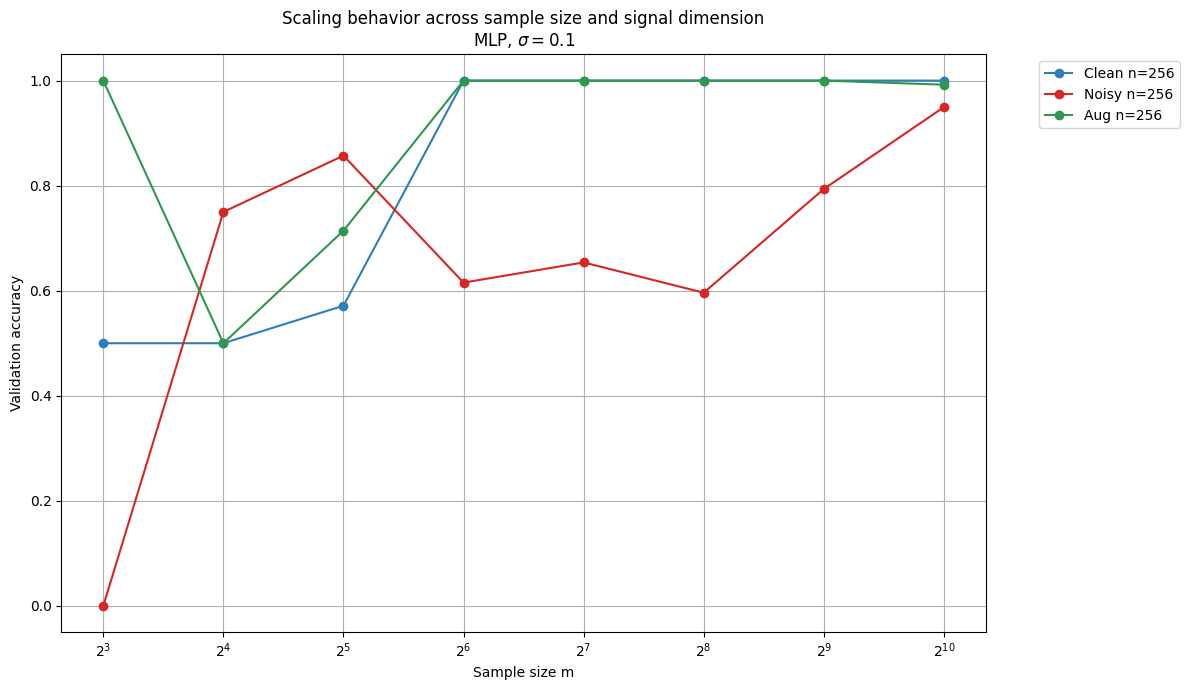

# Gradient over multiple n


Running experiments for n=6

--- n=6, m=8 ---


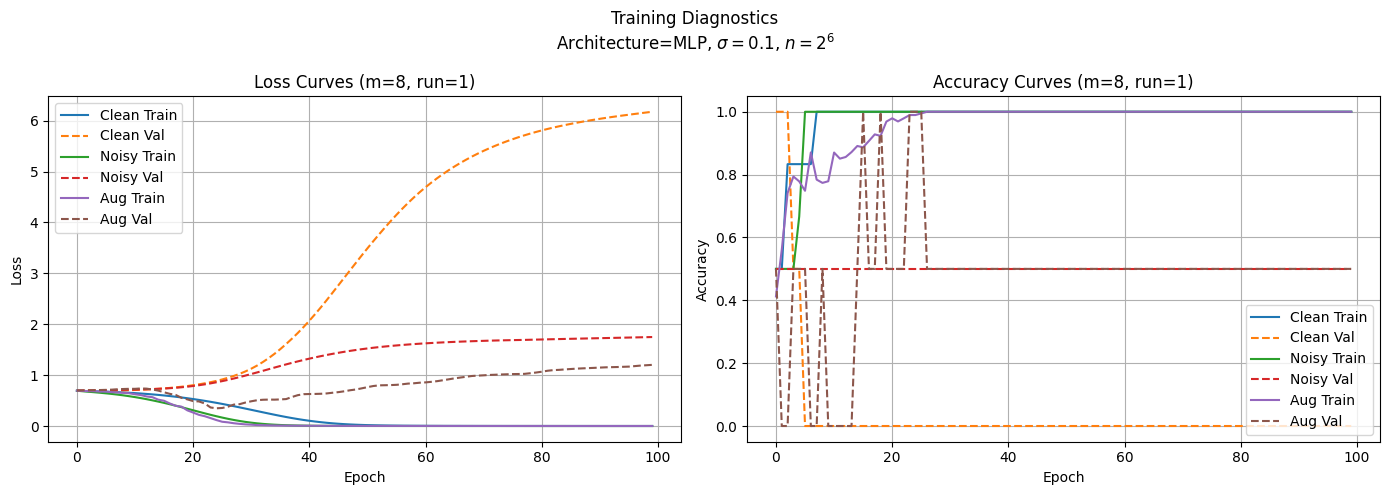

m=8 | clean=1.000, noisy=0.500, aug=1.000

--- n=6, m=16 ---


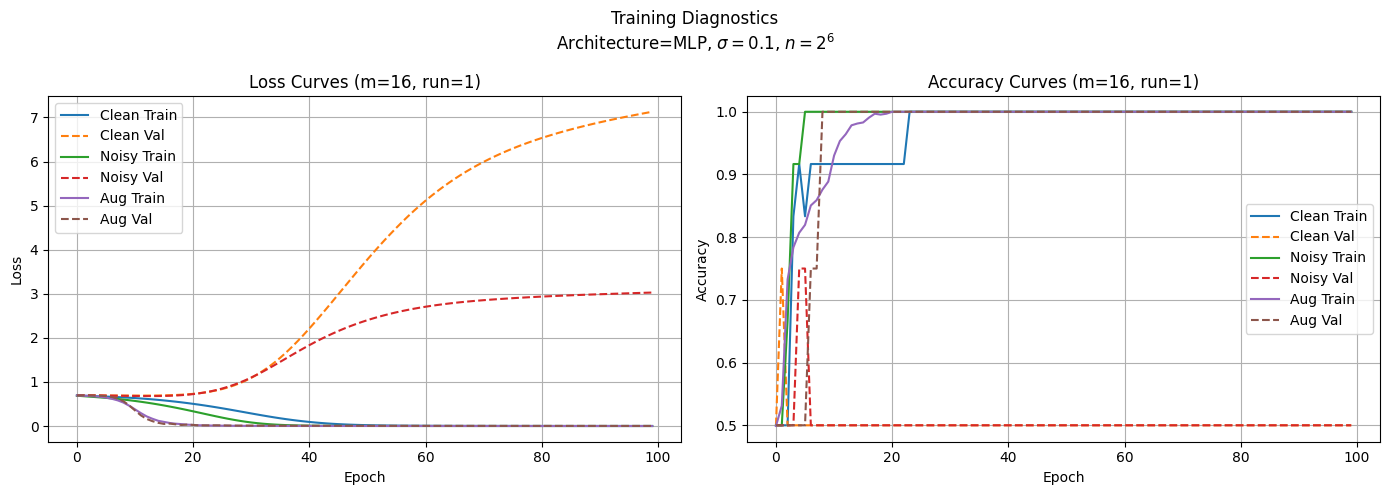

m=16 | clean=0.750, noisy=0.750, aug=1.000

--- n=6, m=32 ---


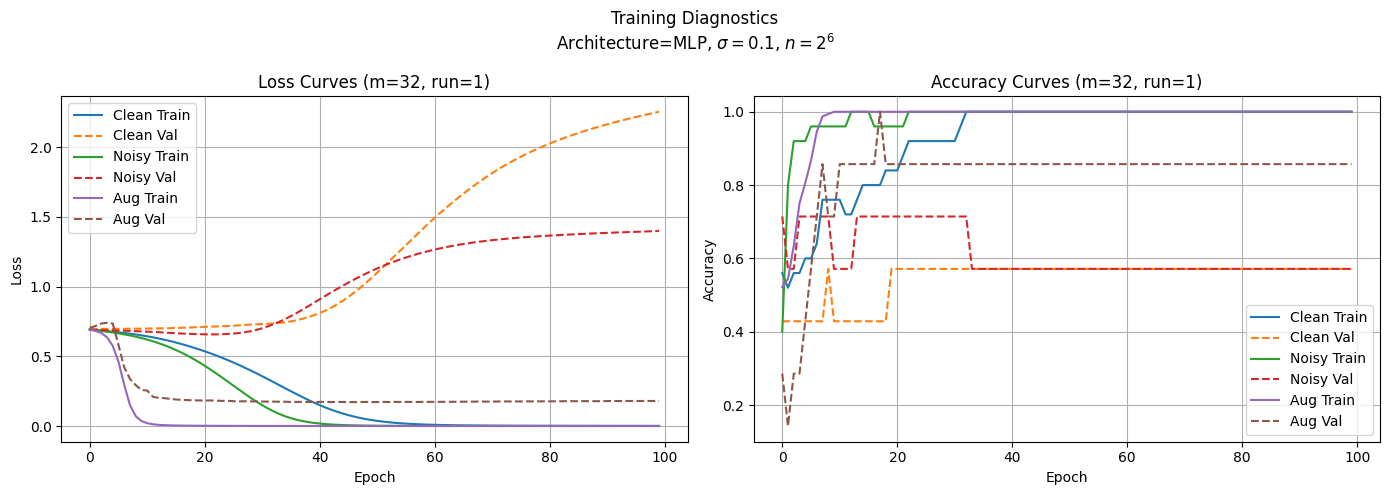

m=32 | clean=0.571, noisy=0.714, aug=1.000

--- n=6, m=64 ---


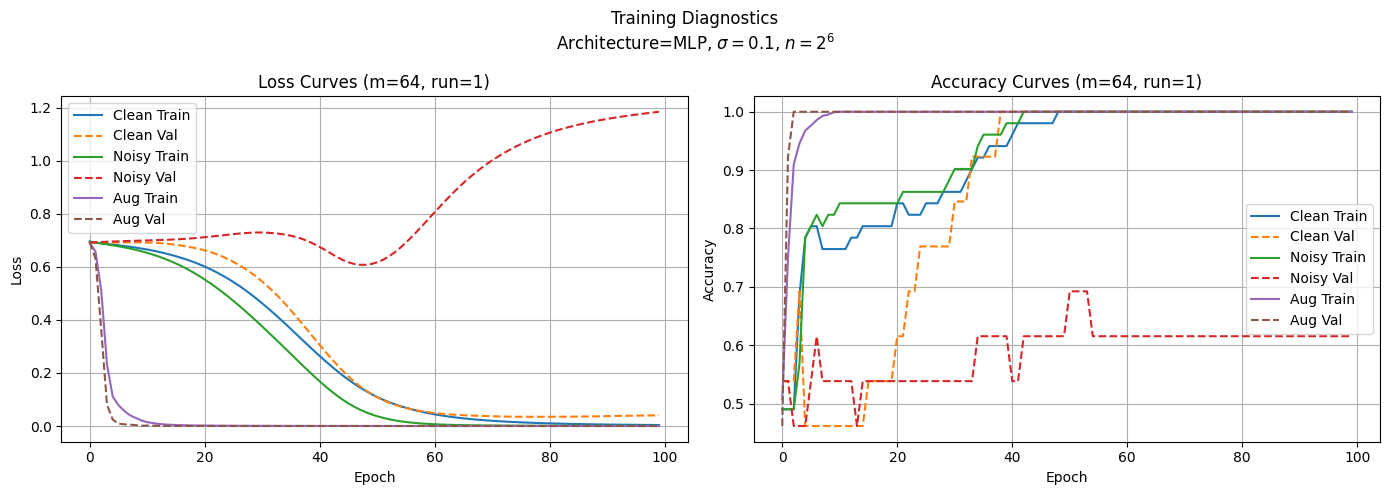

m=64 | clean=1.000, noisy=0.692, aug=1.000

--- n=6, m=128 ---


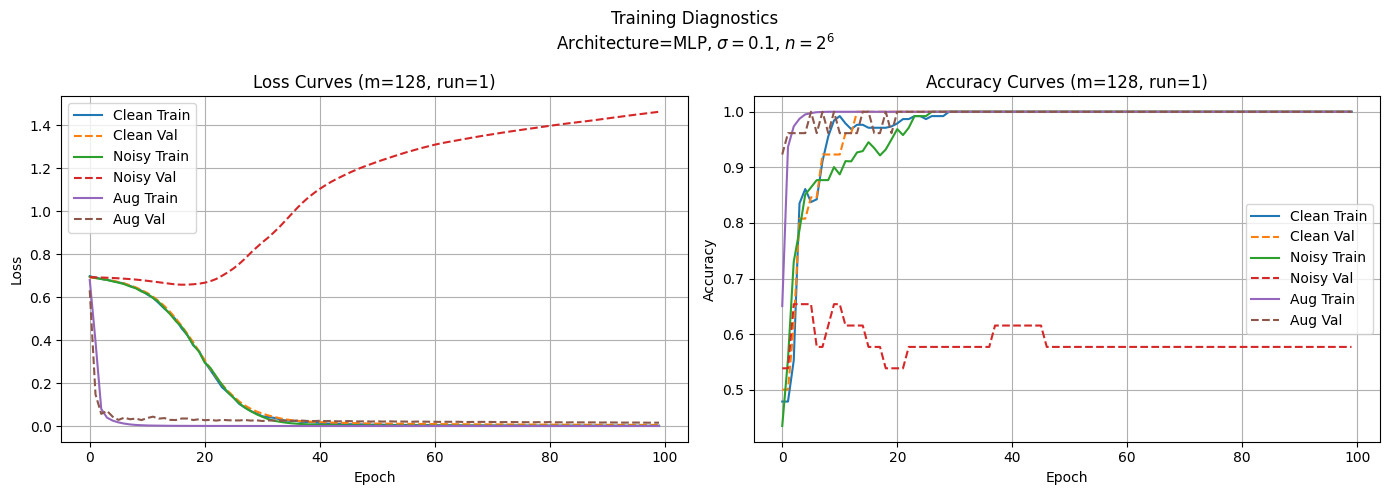

m=128 | clean=1.000, noisy=0.654, aug=1.000

--- n=6, m=256 ---


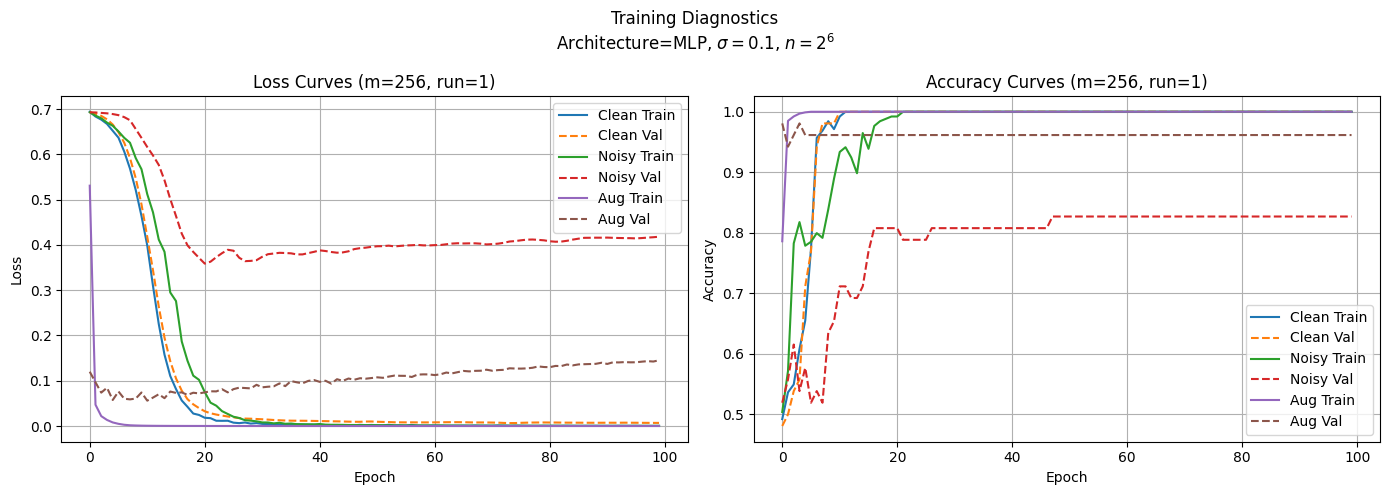

m=256 | clean=1.000, noisy=0.827, aug=0.981
Skipping n=6, m=512 
Skipping n=6, m=1024 

Running experiments for n=7

--- n=7, m=8 ---


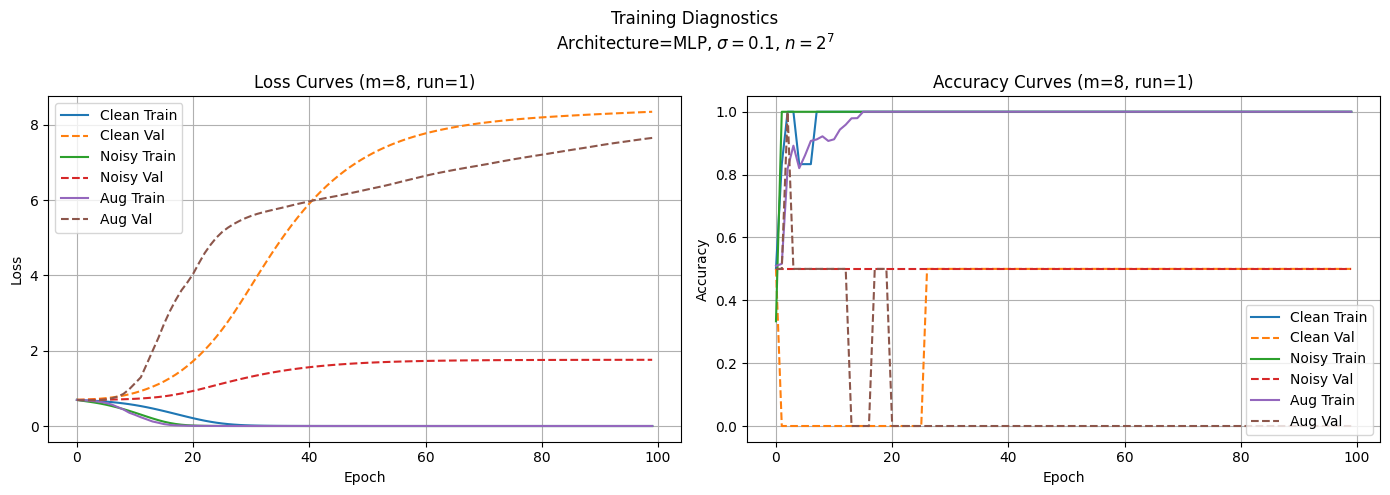

m=8 | clean=0.500, noisy=0.500, aug=1.000

--- n=7, m=16 ---


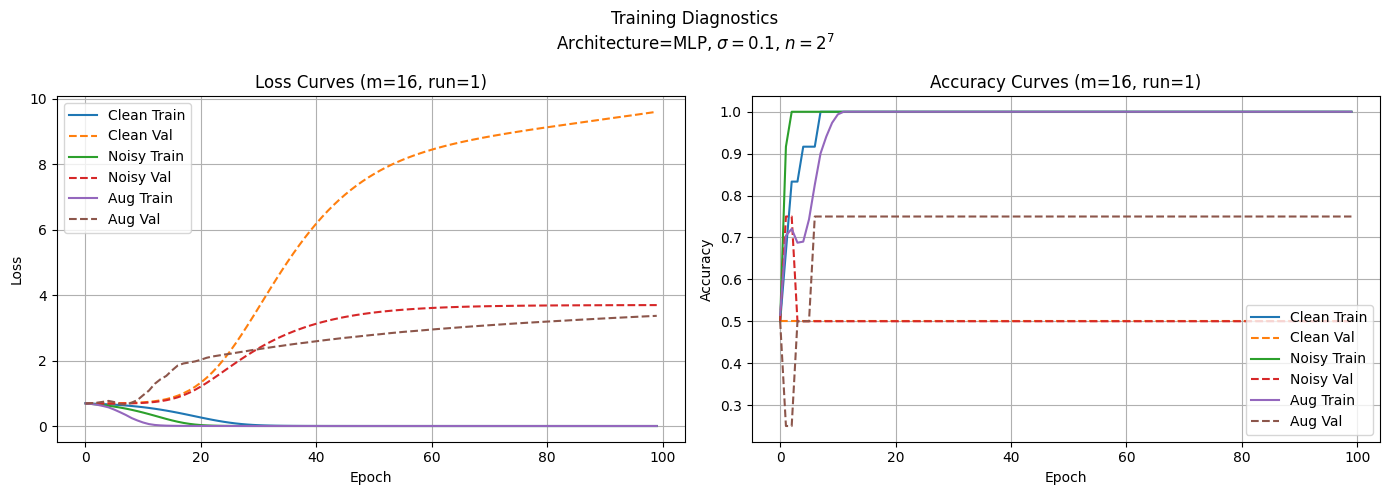

m=16 | clean=0.500, noisy=0.750, aug=0.750

--- n=7, m=32 ---


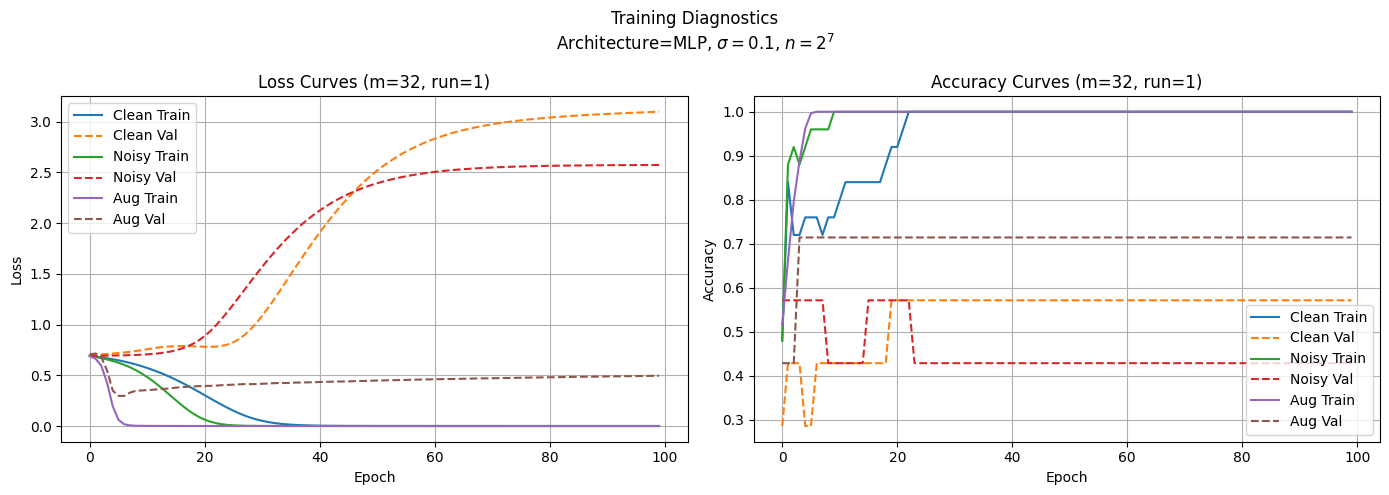

m=32 | clean=0.571, noisy=0.571, aug=0.714

--- n=7, m=64 ---


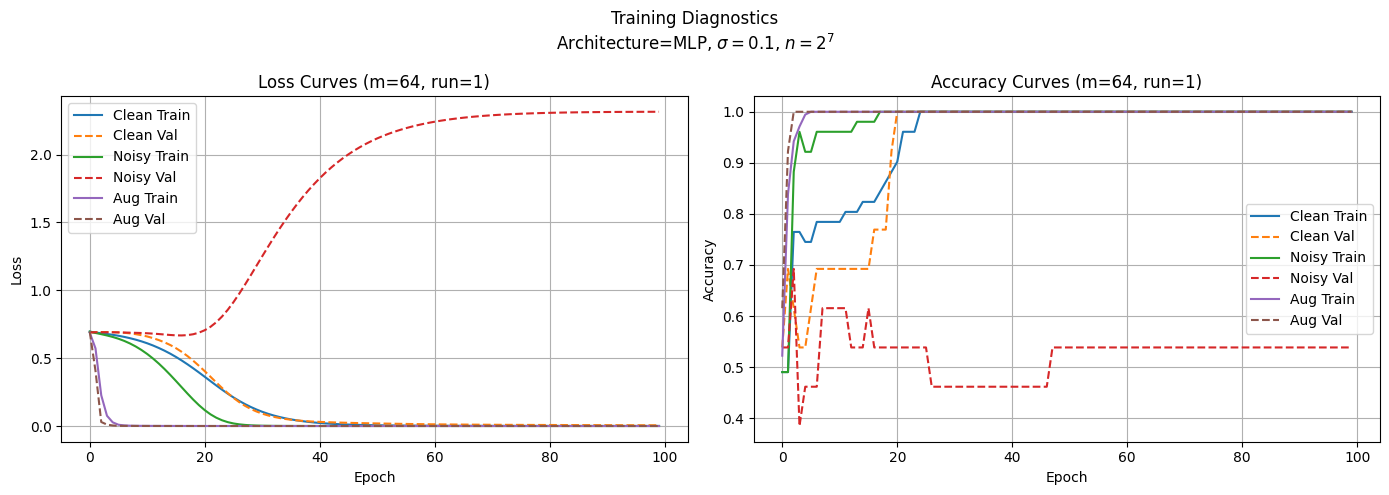

m=64 | clean=1.000, noisy=0.692, aug=1.000

--- n=7, m=128 ---


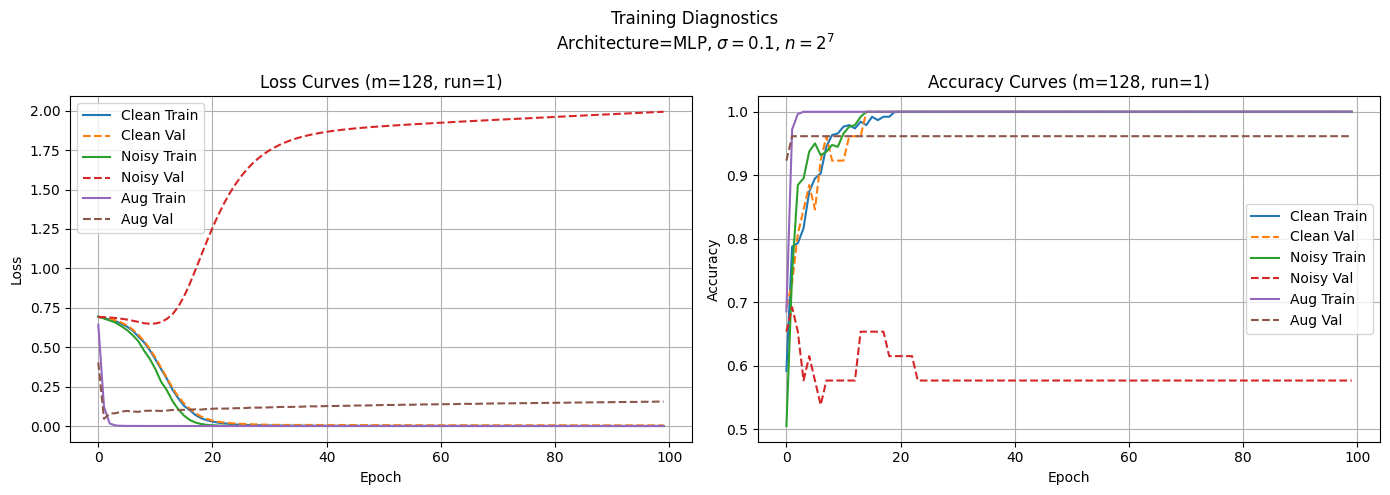

m=128 | clean=1.000, noisy=0.692, aug=0.962

--- n=7, m=256 ---


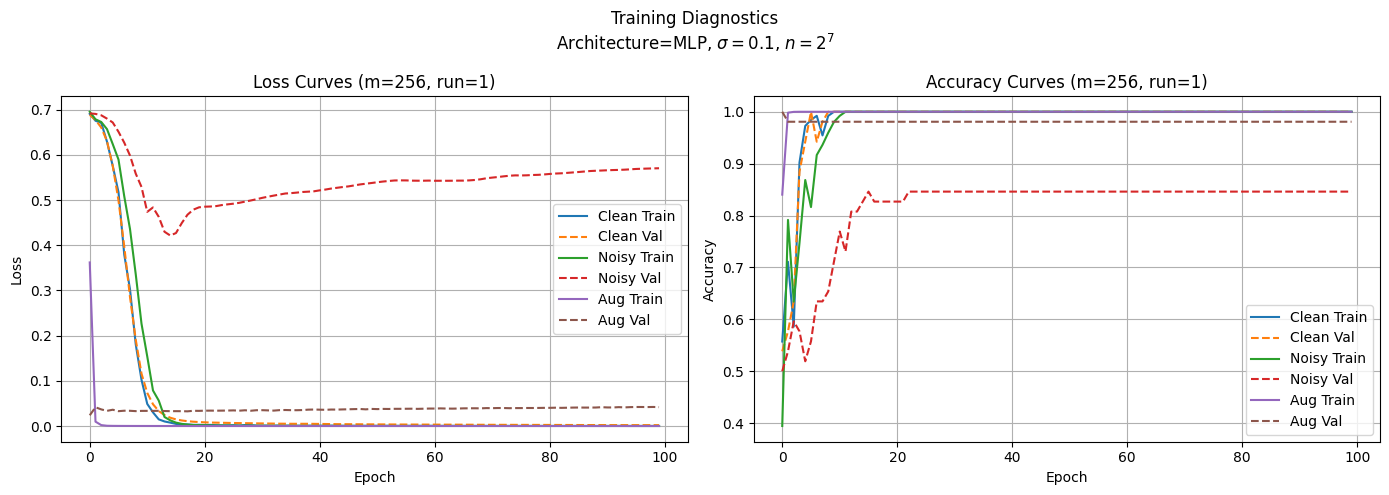

m=256 | clean=1.000, noisy=0.846, aug=1.000

--- n=7, m=512 ---


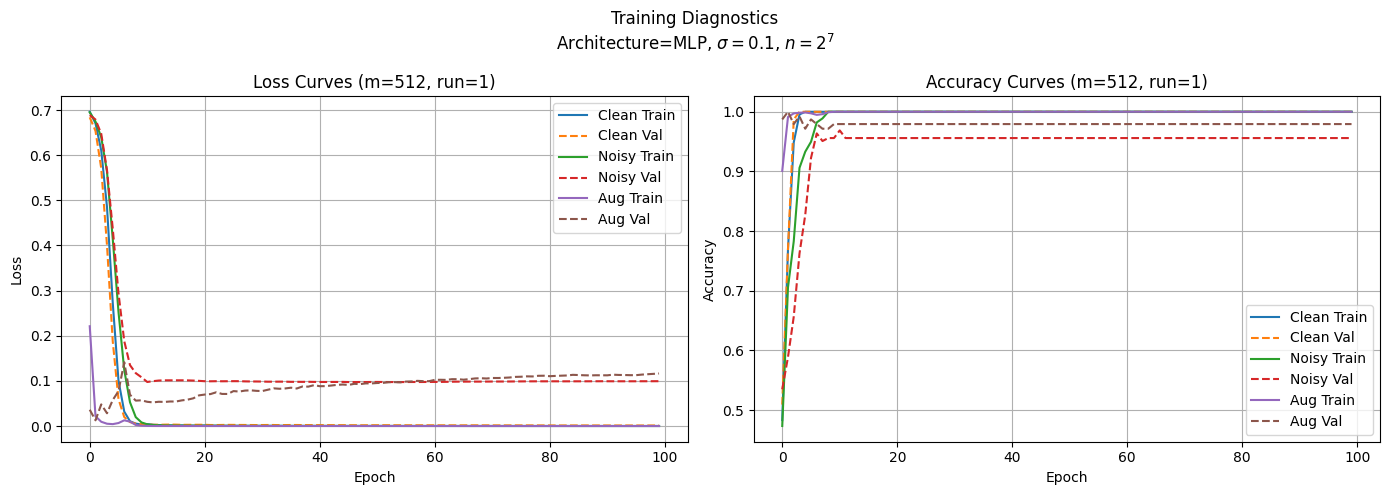

m=512 | clean=1.000, noisy=0.969, aug=1.000
Skipping n=7, m=1024 

Running experiments for n=8

--- n=8, m=8 ---


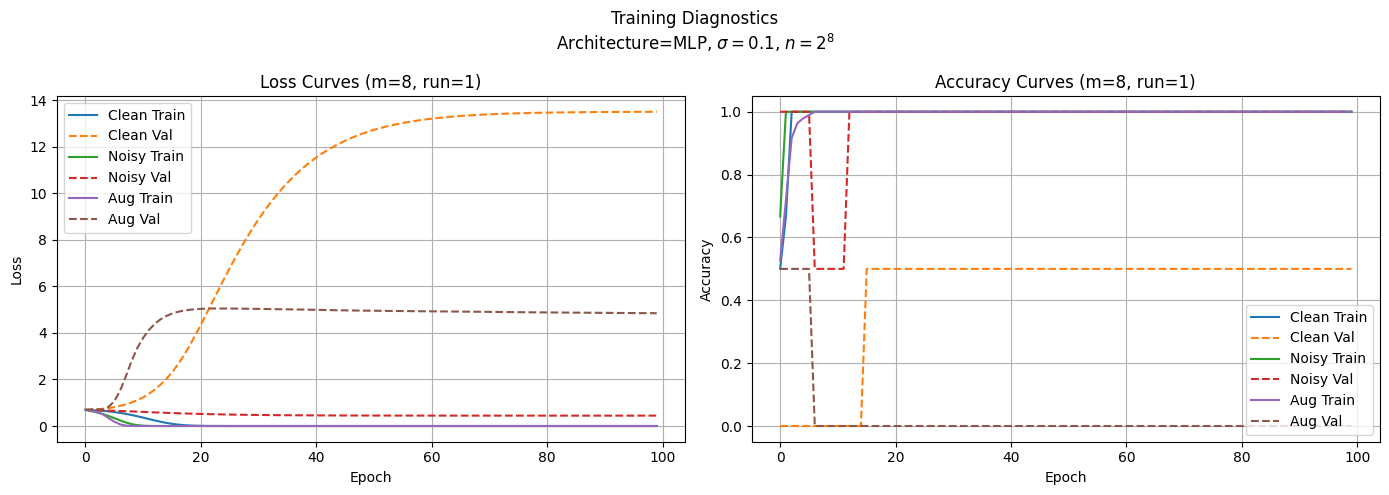

m=8 | clean=0.500, noisy=1.000, aug=0.500

--- n=8, m=16 ---


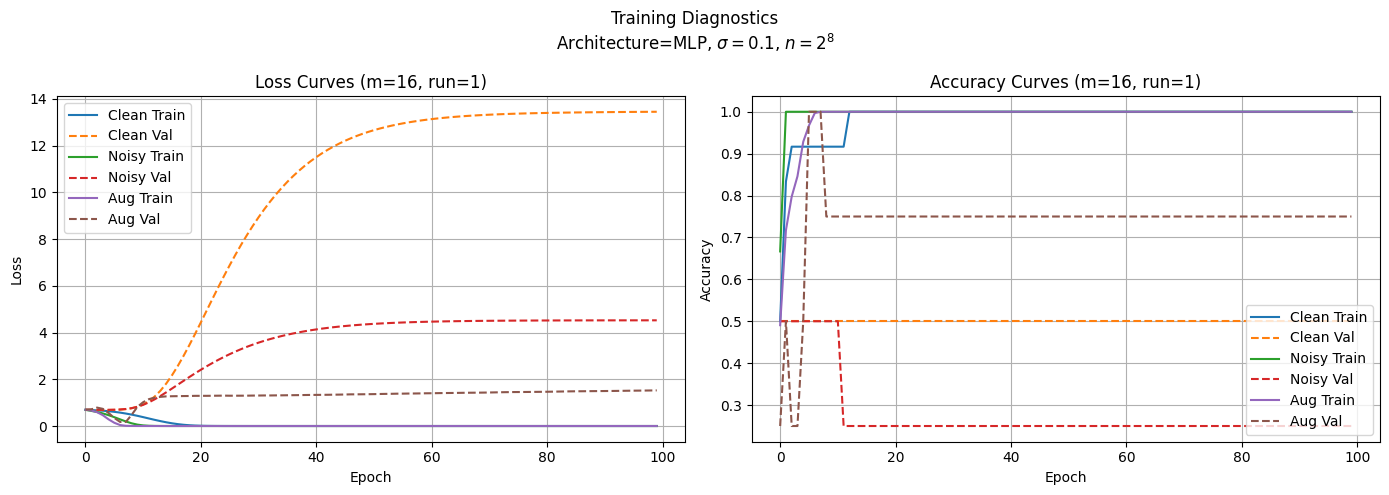

m=16 | clean=0.500, noisy=0.500, aug=1.000

--- n=8, m=32 ---


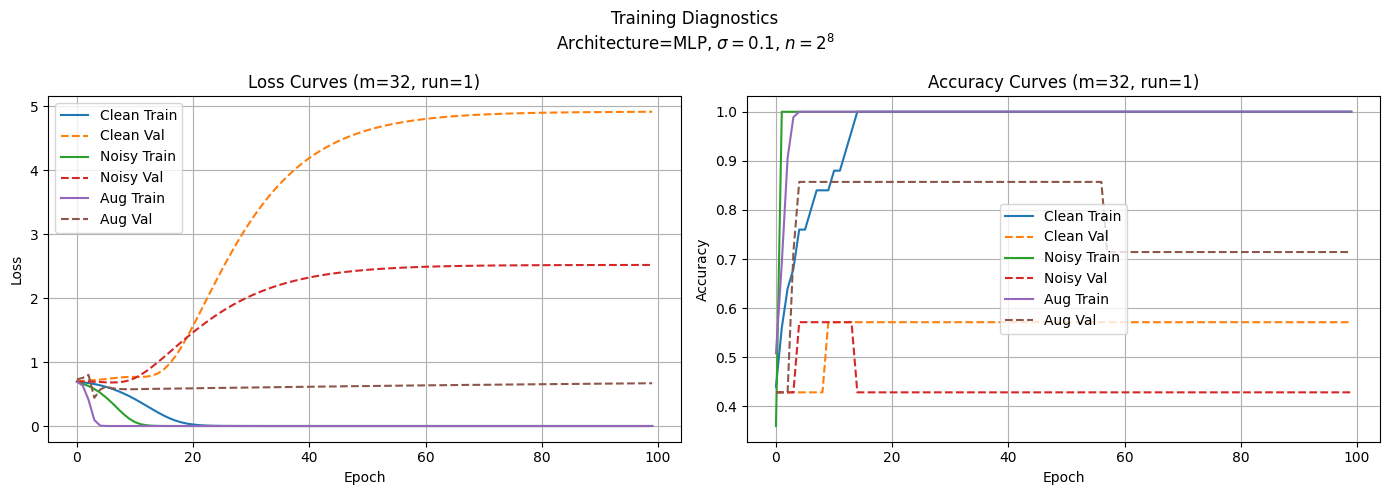

m=32 | clean=0.571, noisy=0.571, aug=0.857

--- n=8, m=64 ---


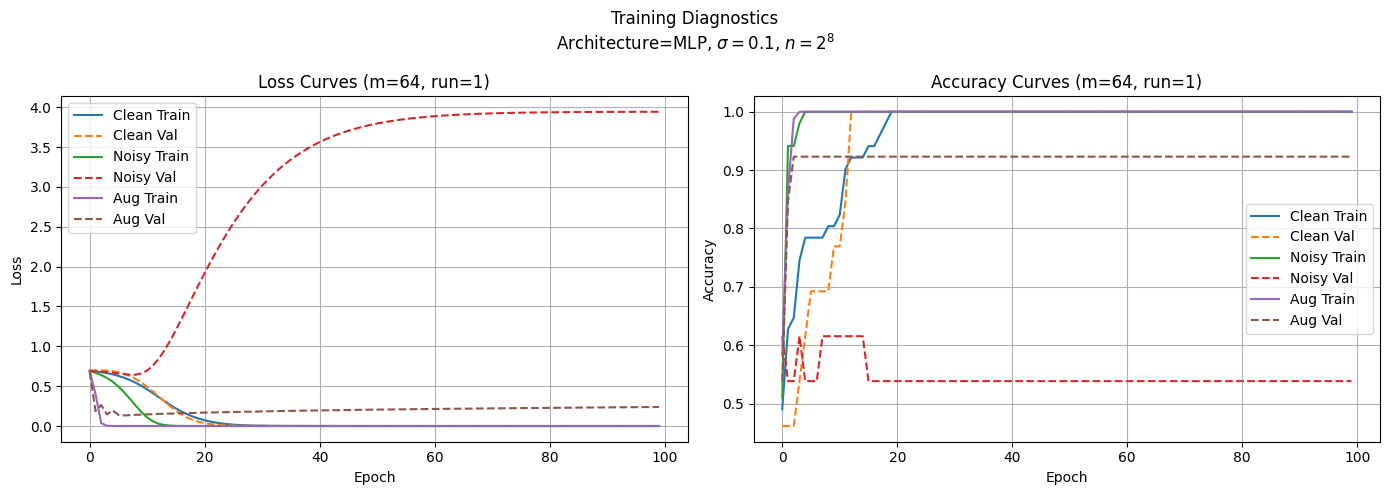

m=64 | clean=1.000, noisy=0.615, aug=0.923

--- n=8, m=128 ---


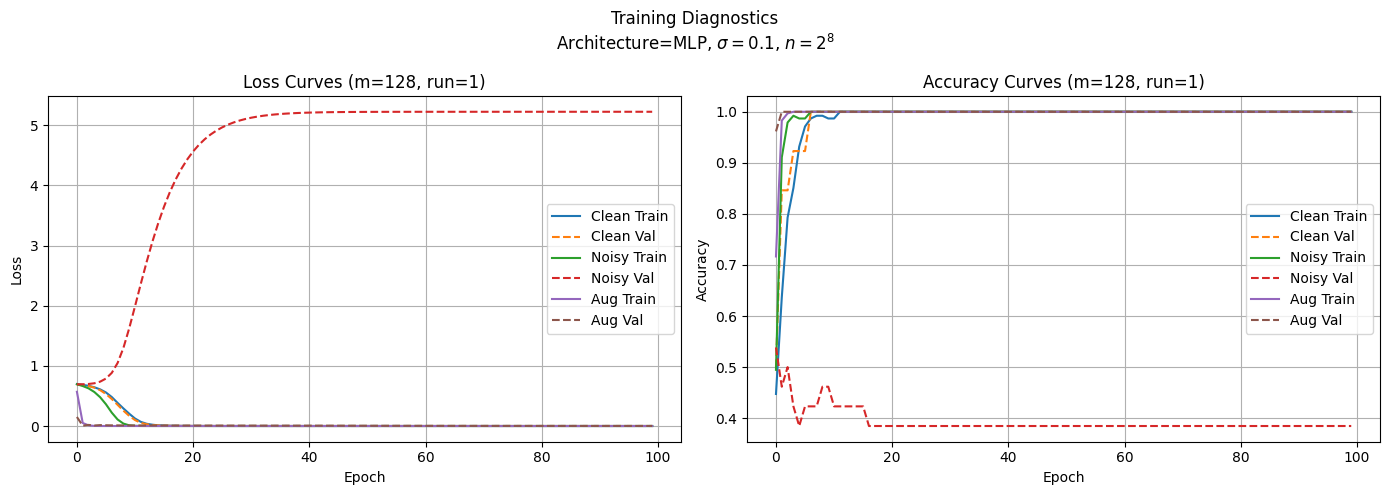

m=128 | clean=1.000, noisy=0.538, aug=1.000

--- n=8, m=256 ---


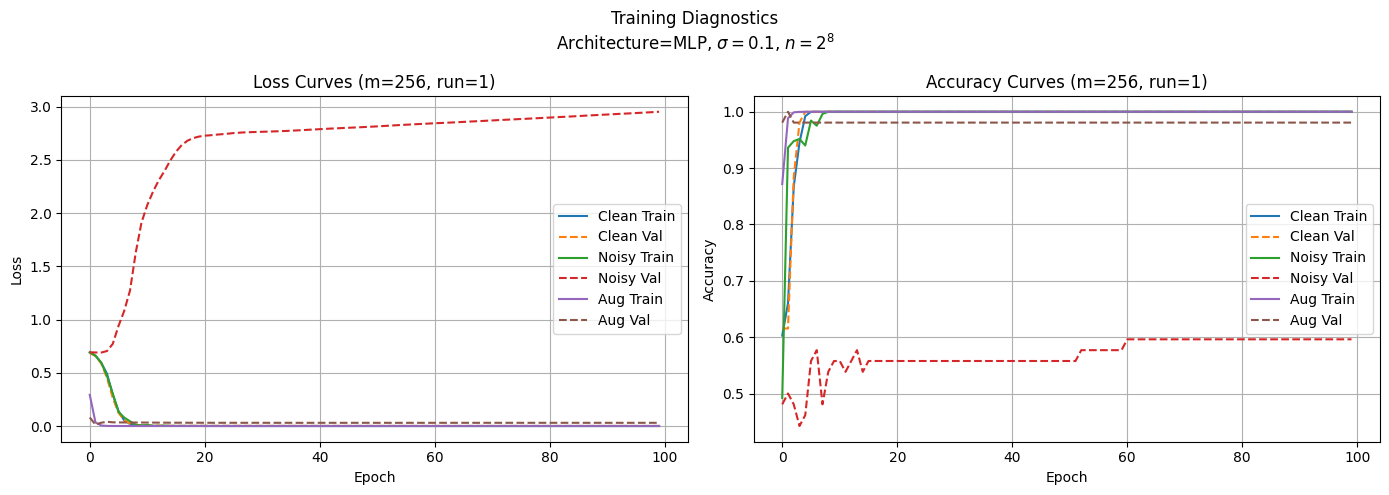

m=256 | clean=1.000, noisy=0.596, aug=1.000

--- n=8, m=512 ---


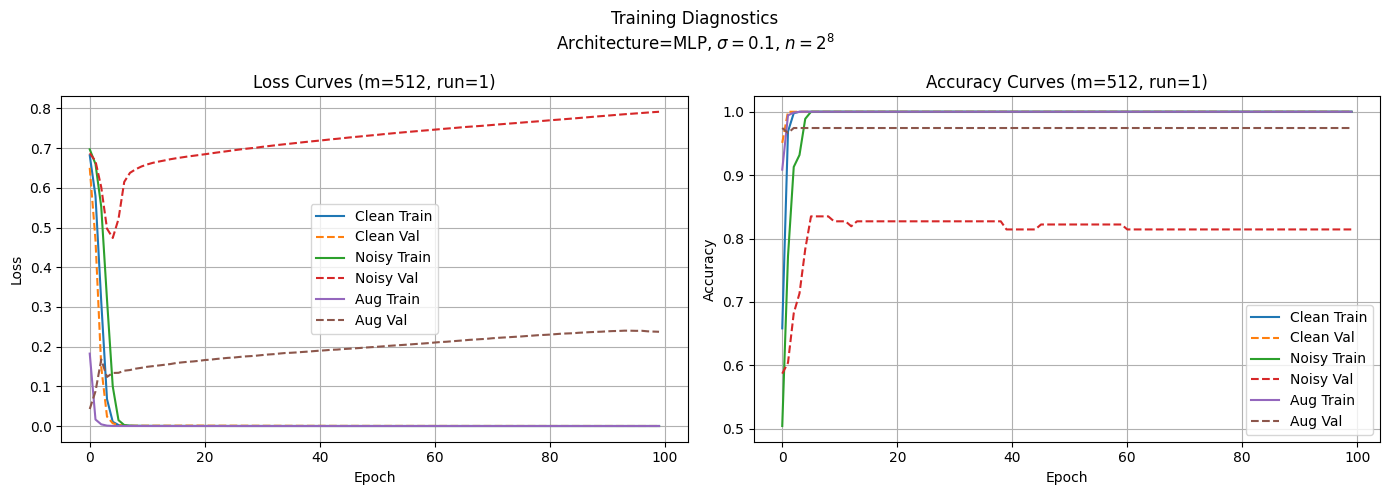

m=512 | clean=1.000, noisy=0.835, aug=0.974

--- n=8, m=1024 ---


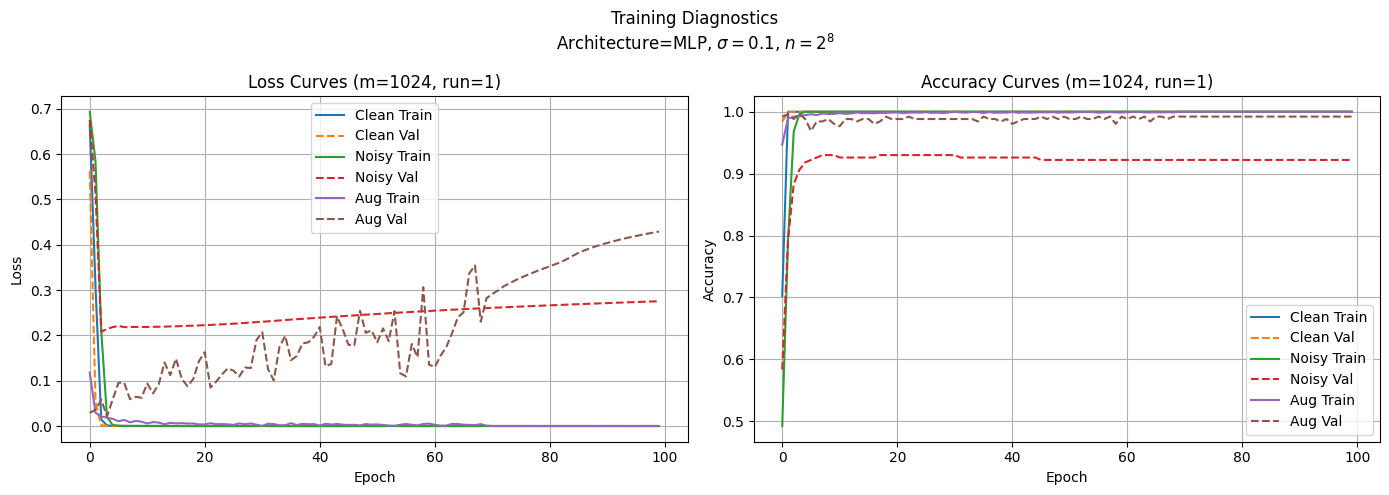

m=1024 | clean=1.000, noisy=0.930, aug=0.996

Running experiments for n=9

--- n=9, m=8 ---


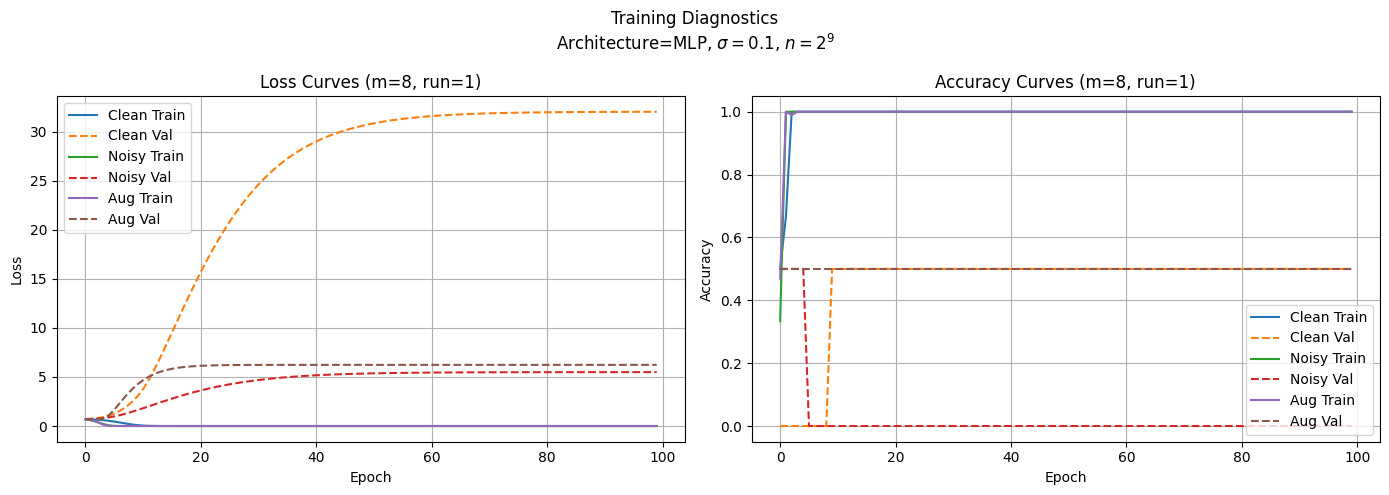

m=8 | clean=0.500, noisy=0.500, aug=0.500

--- n=9, m=16 ---


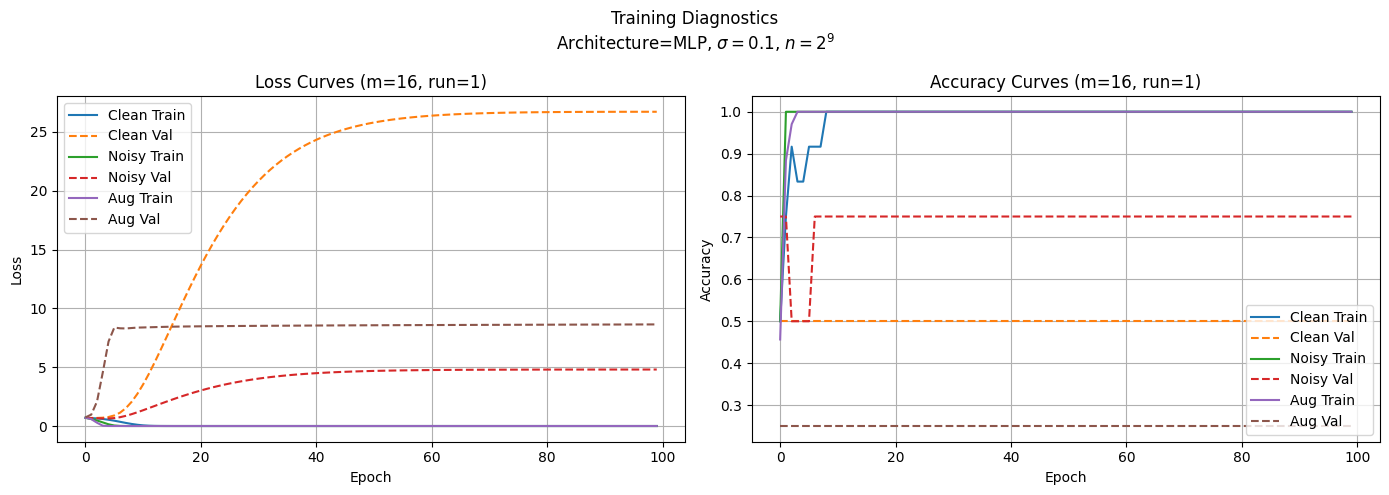

m=16 | clean=0.500, noisy=0.750, aug=0.250

--- n=9, m=32 ---


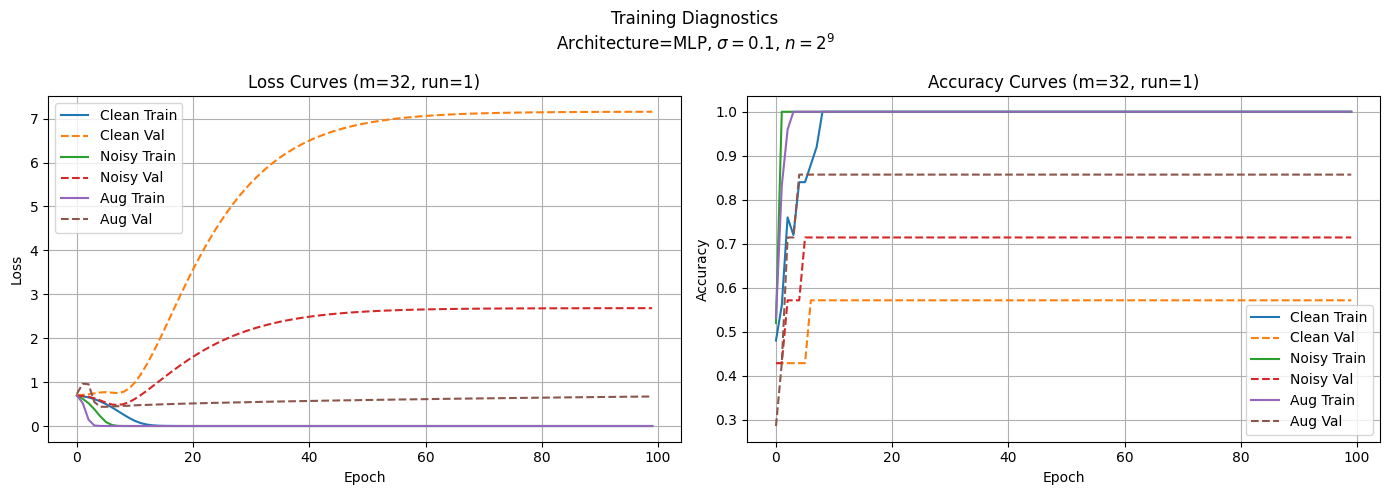

m=32 | clean=0.571, noisy=0.714, aug=0.857

--- n=9, m=64 ---


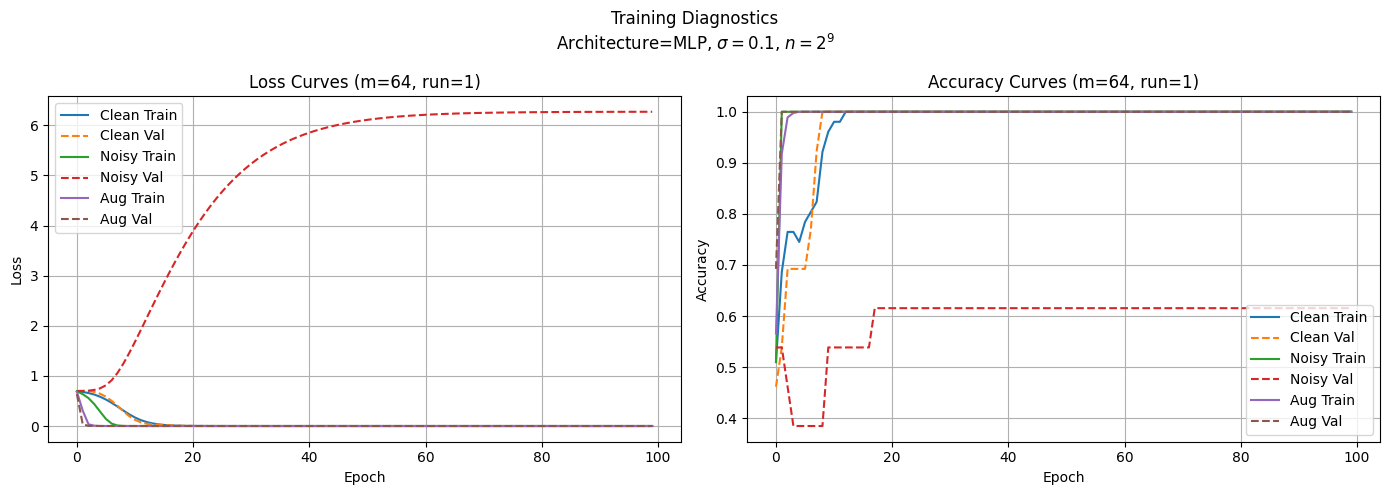

m=64 | clean=1.000, noisy=0.615, aug=1.000

--- n=9, m=128 ---


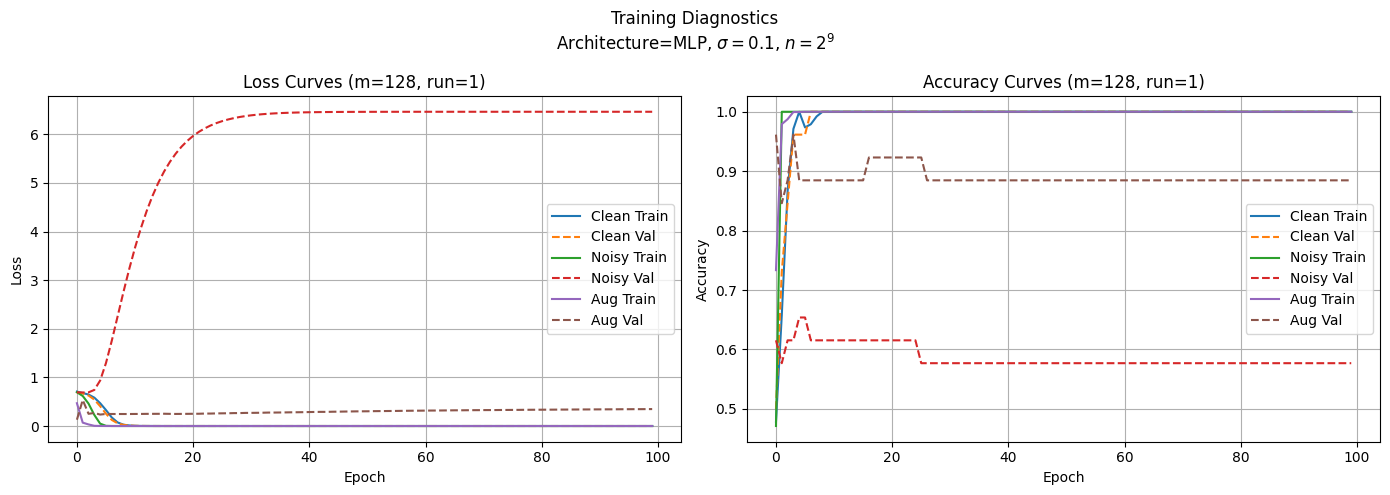

m=128 | clean=1.000, noisy=0.654, aug=0.962

--- n=9, m=256 ---


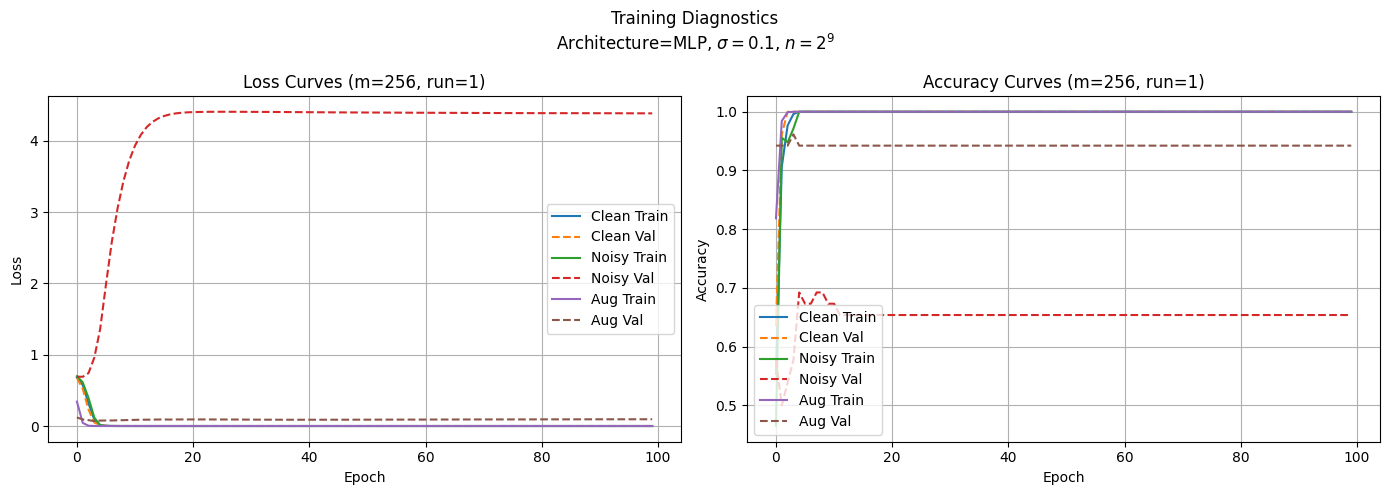

m=256 | clean=1.000, noisy=0.692, aug=0.962

--- n=9, m=512 ---


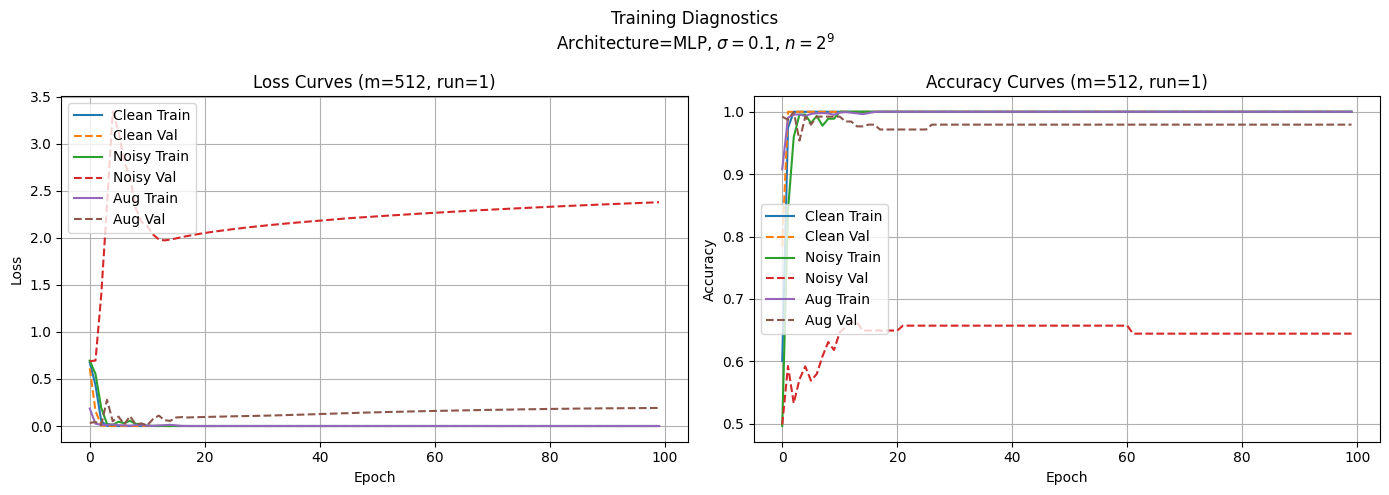

m=512 | clean=1.000, noisy=0.662, aug=1.000

--- n=9, m=1024 ---


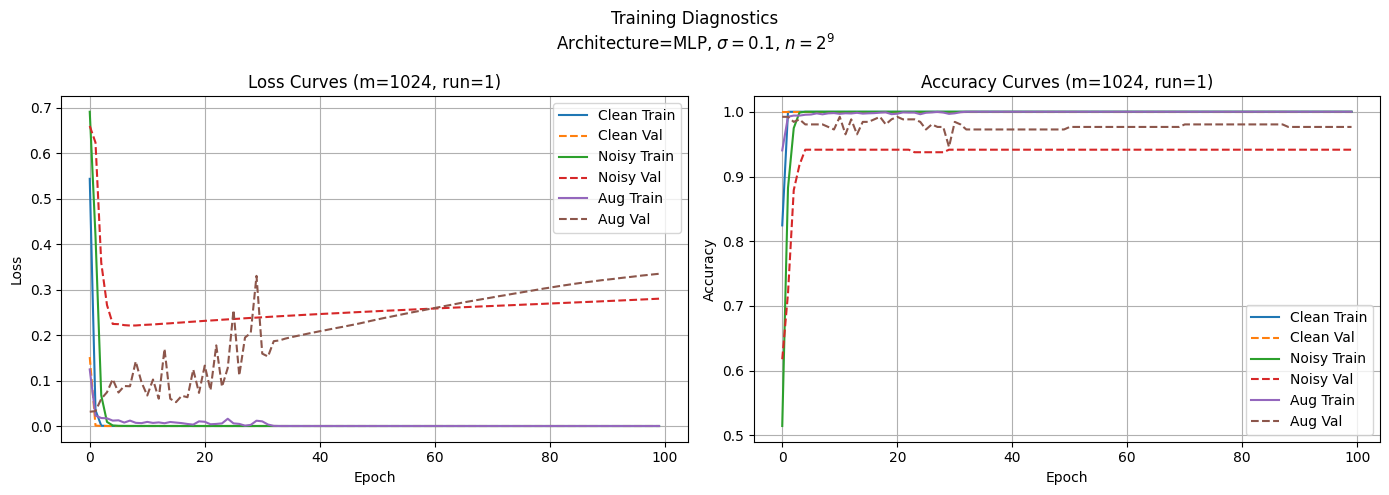

m=1024 | clean=1.000, noisy=0.941, aug=0.992

Running experiments for n=10

--- n=10, m=8 ---


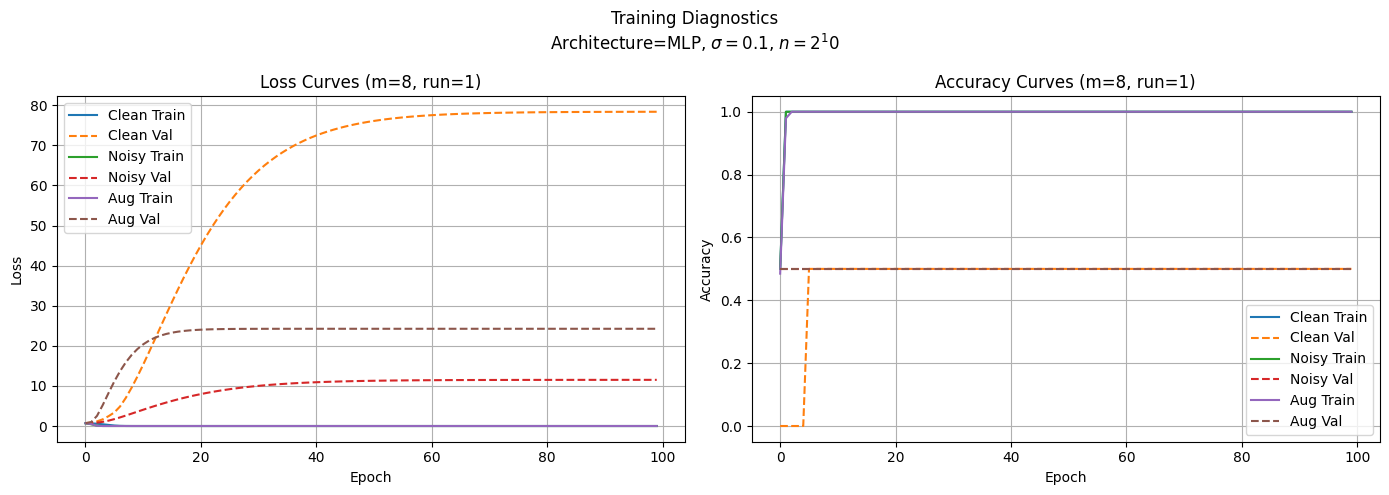

m=8 | clean=0.500, noisy=0.500, aug=0.500

--- n=10, m=16 ---


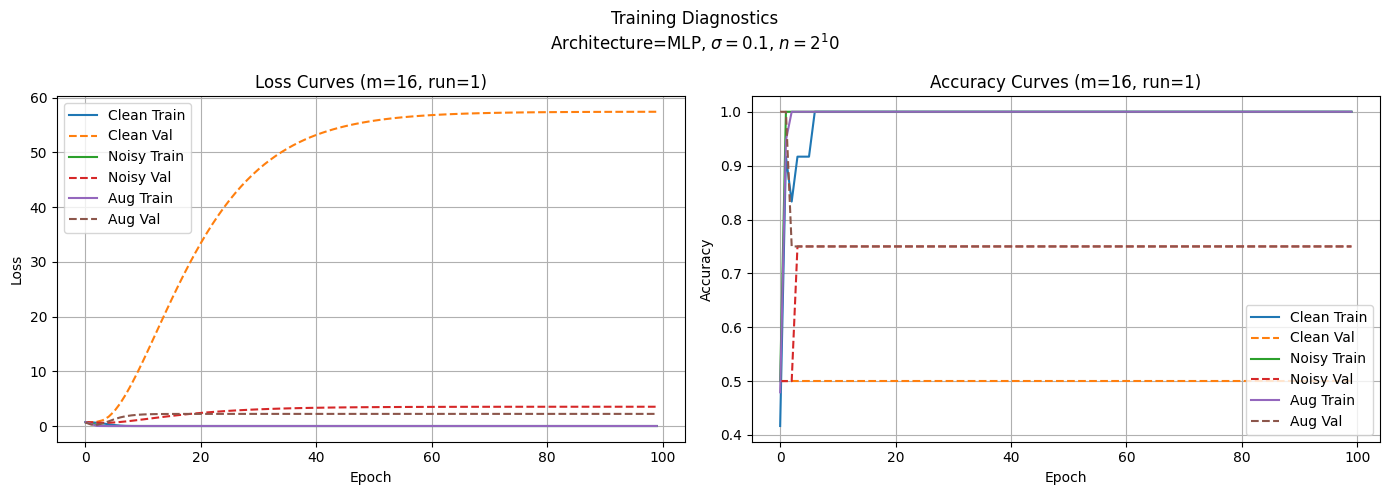

m=16 | clean=0.500, noisy=0.750, aug=1.000

--- n=10, m=32 ---


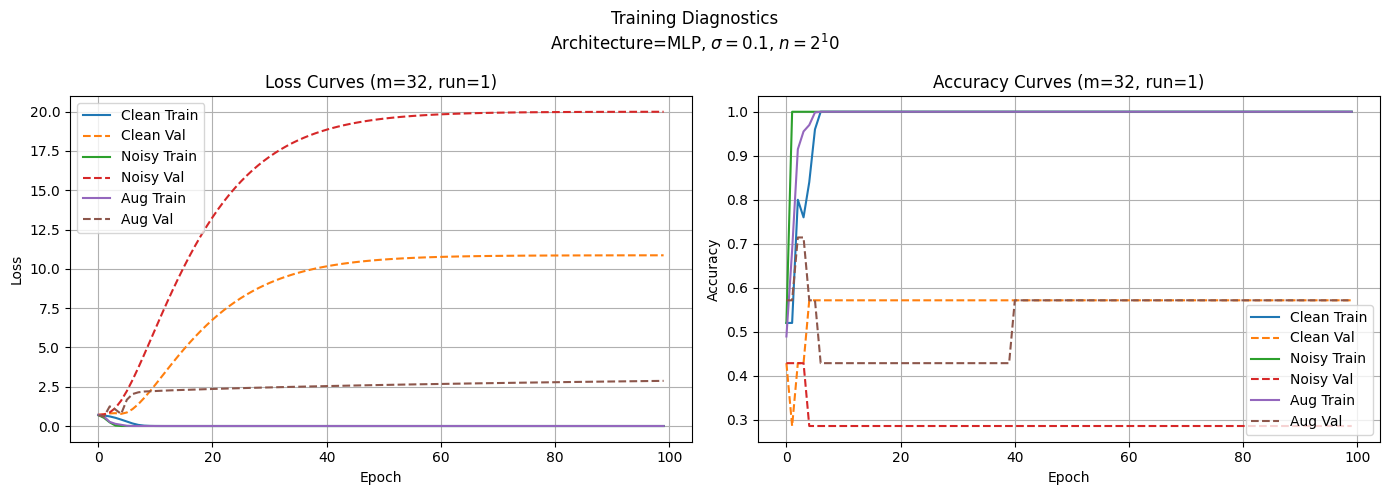

m=32 | clean=0.571, noisy=0.429, aug=0.714

--- n=10, m=64 ---


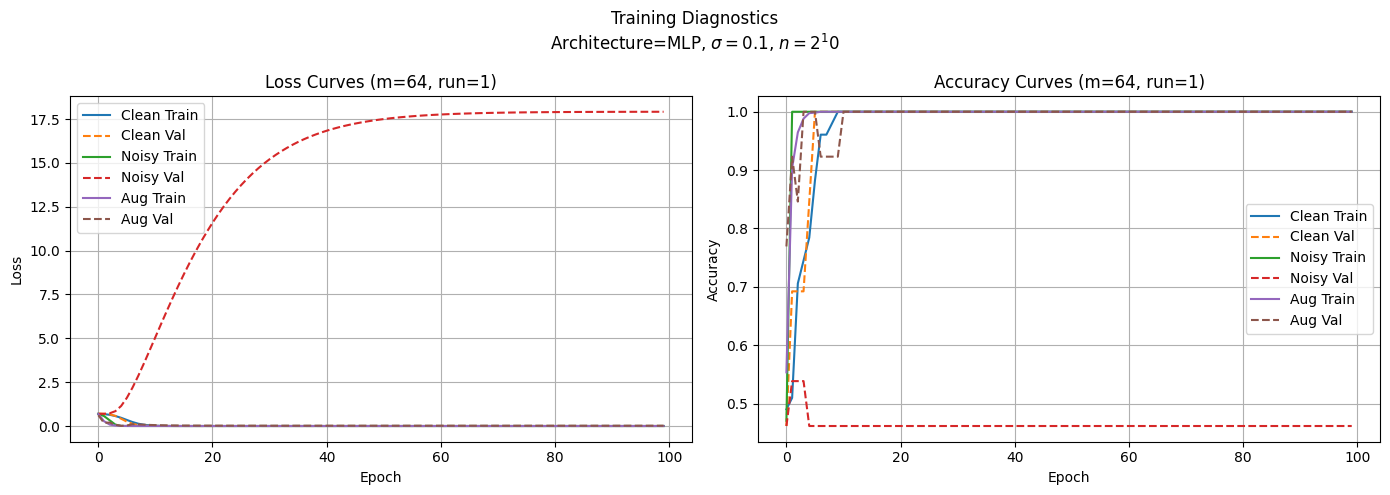

m=64 | clean=1.000, noisy=0.538, aug=1.000

--- n=10, m=128 ---


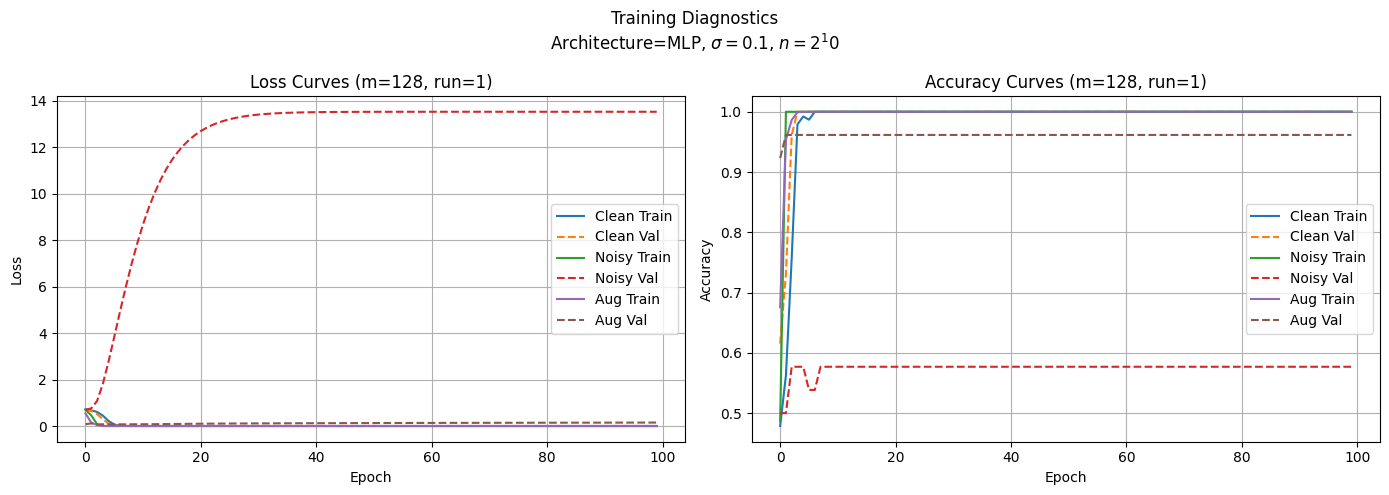

m=128 | clean=1.000, noisy=0.577, aug=0.962

--- n=10, m=256 ---


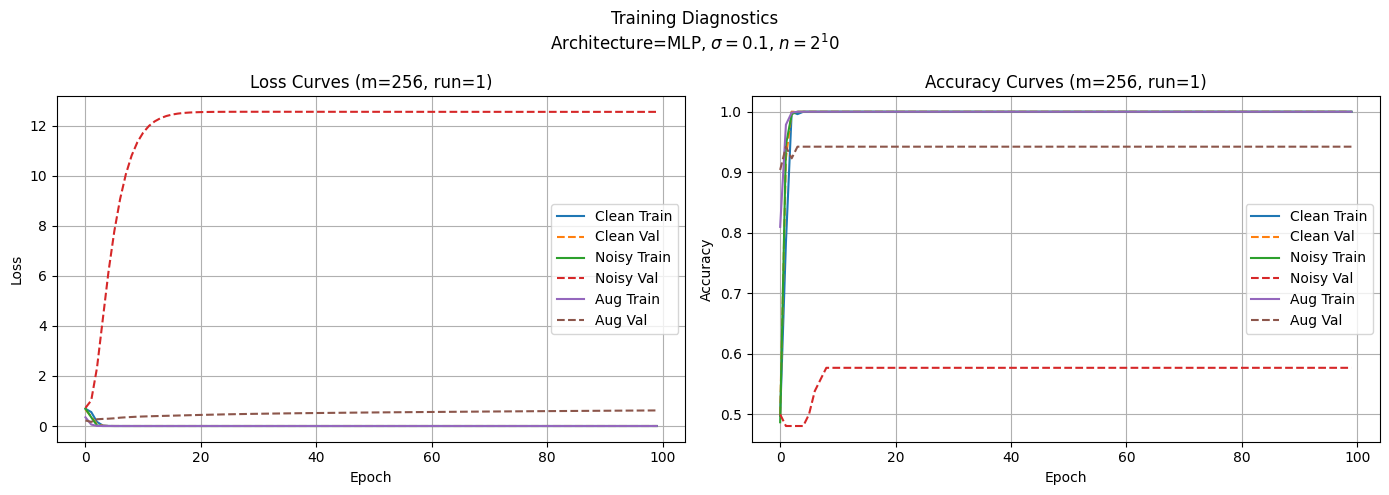

m=256 | clean=1.000, noisy=0.577, aug=0.942

--- n=10, m=512 ---


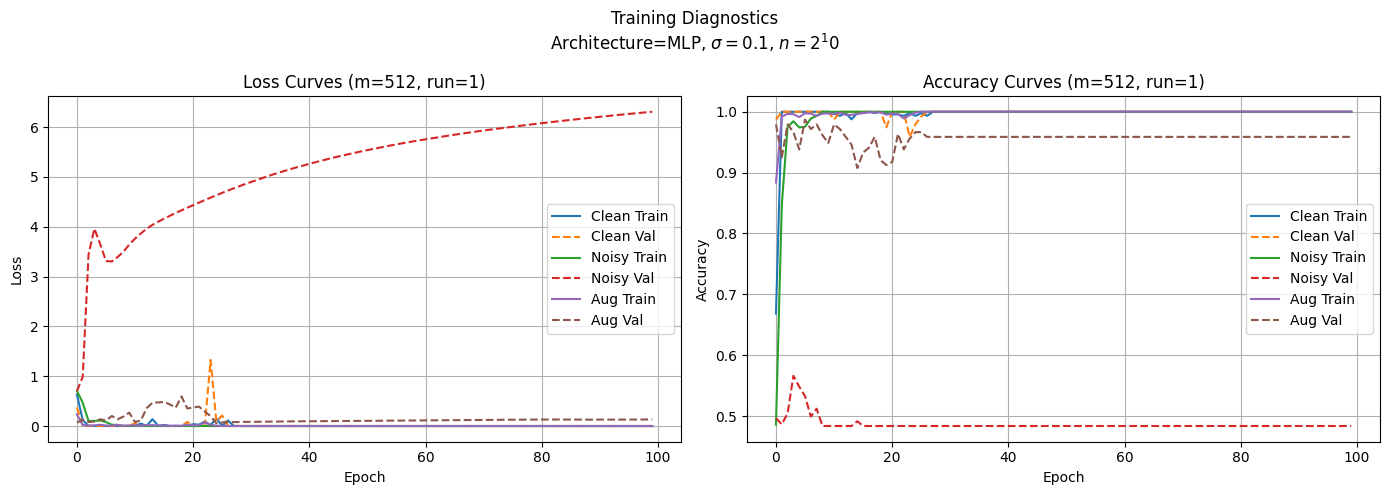

m=512 | clean=1.000, noisy=0.566, aug=0.987

--- n=10, m=1024 ---


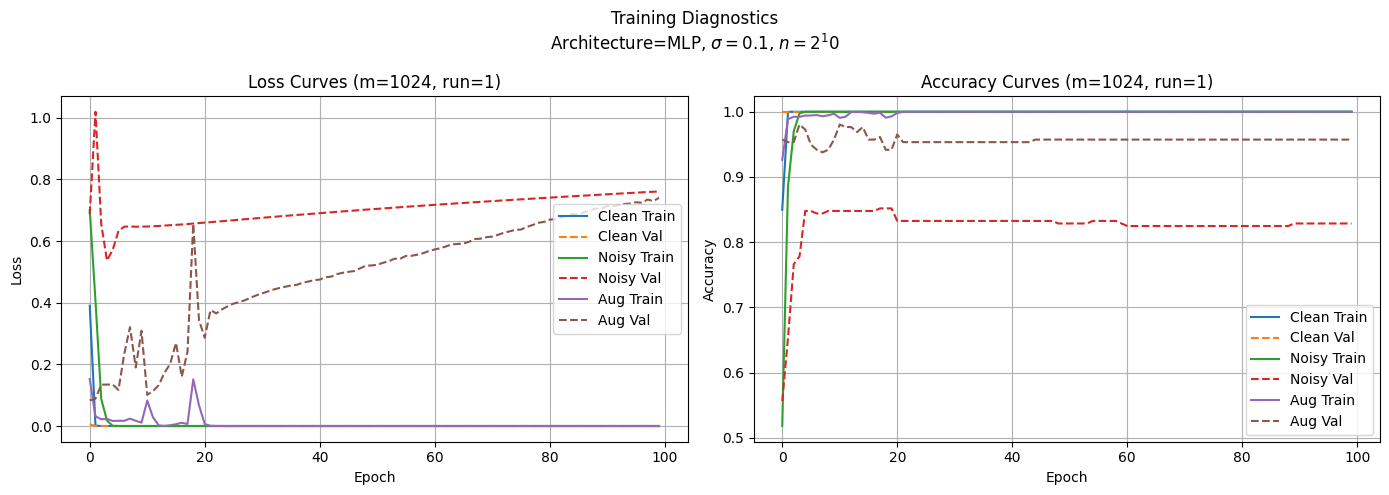

m=1024 | clean=1.000, noisy=0.852, aug=0.980


ValueError: x and y must have same first dimension, but have shapes (8,) and (6,)

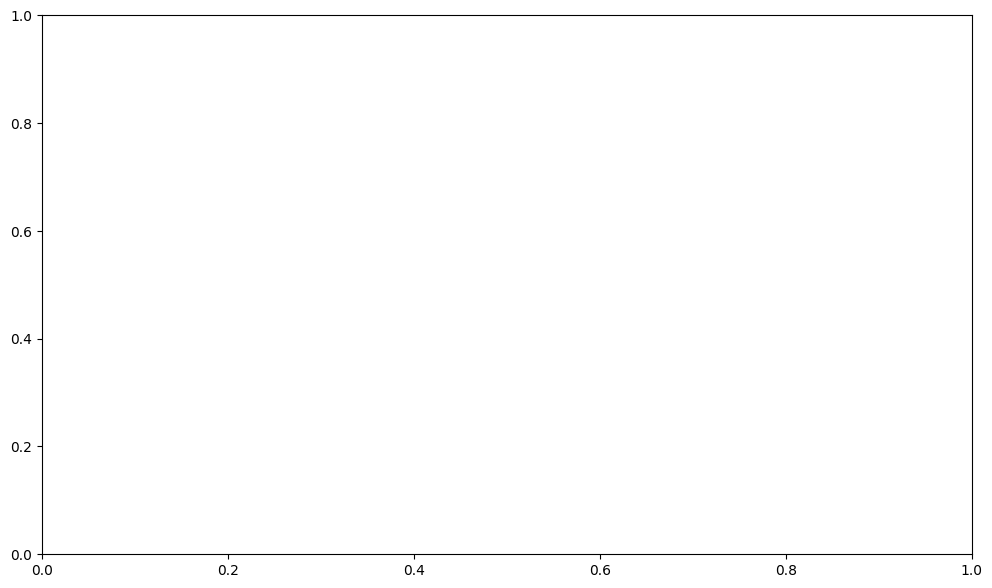

In [29]:
results = run_experiment(
    load_dataset=lambda n: load_dataset(n),
    build_dataloaders=build_dataloaders,
    arch="MLP",
    N_VALUES=N_VALUES,
    M_VALUES=M_VALUES,
    sigma=SIGMA,
    r=R,
    n_runs=N_RUNS,
    device=DEVICE,
    max_epochs=MAX_EPOCHS,
    arch_configs=ARCH_CONFIGS,
    do_early_stopping=False,
)

# Plot 2

In [ ]:
def plot_improvement_vs_n(
    results,
    N_VALUES,
    M_VALUES,
    fixed_m,
    arch="MLP",
    sigma=0.1,
    r=2,
):

    # ============================================
    # FIND INDEX OF FIXED m
    # ============================================

    if fixed_m not in M_VALUES:
        raise ValueError(
            f"fixed_m={fixed_m} not in M_VALUES"
        )

    m_idx = M_VALUES.index(fixed_m)

    # ============================================
    # EXTRACT CURVES
    # ============================================

    aug_vs_noisy_abs = []
    aug_vs_noisy_pct = []

    aug_vs_clean_abs = []
    aug_vs_clean_pct = []

    for n in N_VALUES:

        clean = results["clean"][n][m_idx]
        noisy = results["noisy"][n][m_idx]
        aug = results["augmented"][n][m_idx]

        # ----------------------------------------
        # AUG vs NOISY
        # ----------------------------------------

        abs_noisy = aug - noisy

        if noisy == 0:
            pct_noisy = np.nan
        else:
            pct_noisy = 100 * abs_noisy / noisy

        aug_vs_noisy_abs.append(abs_noisy)
        aug_vs_noisy_pct.append(pct_noisy)

        # ----------------------------------------
        # AUG vs CLEAN
        # ----------------------------------------

        abs_clean = aug - clean

        if clean == 0:
            pct_clean = np.nan
        else:
            pct_clean = 100 * abs_clean / clean

        aug_vs_clean_abs.append(abs_clean)
        aug_vs_clean_pct.append(pct_clean)

    # ============================================
    # PLOTTING
    # ============================================

    fig, axs = plt.subplots(
        2,
        2,
        figsize=(14, 10)
    )

    # ==================================================
    # 1) AUG vs NOISY (ABS)
    # ==================================================

    axs[0, 0].plot(
        N_VALUES,
        aug_vs_noisy_abs,
        marker="o"
    )

    axs[0, 0].axhline(
        0,
        linestyle="--"
    )

    axs[0, 0].set_title(
        "Absolute Accuracy Gain\nAugmented vs Noisy"
    )

    axs[0, 0].set_xlabel("System size n")
    axs[0, 0].set_ylabel("Accuracy difference")

    axs[0, 0].grid(True)

    # ==================================================
    # 2) AUG vs NOISY (%)
    # ==================================================

    axs[0, 1].plot(
        N_VALUES,
        aug_vs_noisy_pct,
        marker="o"
    )

    axs[0, 1].axhline(
        0,
        linestyle="--"
    )

    axs[0, 1].set_title(
        "Percentage Accuracy Gain\nAugmented vs Noisy"
    )

    axs[0, 1].set_xlabel("System size n")
    axs[0, 1].set_ylabel("% improvement")

    axs[0, 1].grid(True)

    # ==================================================
    # 3) AUG vs CLEAN (ABS)
    # ==================================================

    axs[1, 0].plot(
        N_VALUES,
        aug_vs_clean_abs,
        marker="o"
    )

    axs[1, 0].axhline(
        0,
        linestyle="--"
    )

    axs[1, 0].set_title(
        "Absolute Accuracy Difference\nAugmented vs Clean"
    )

    axs[1, 0].set_xlabel("System size n")
    axs[1, 0].set_ylabel("Accuracy difference")

    axs[1, 0].grid(True)

    # ==================================================
    # 4) AUG vs CLEAN (%)
    # ==================================================

    axs[1, 1].plot(
        N_VALUES,
        aug_vs_clean_pct,
        marker="o"
    )

    axs[1, 1].axhline(
        0,
        linestyle="--"
    )

    axs[1, 1].set_title(
        "Percentage Accuracy Difference\nAugmented vs Clean"
    )

    axs[1, 1].set_xlabel("System size n")
    axs[1, 1].set_ylabel("% difference")

    axs[1, 1].grid(True)

    # ==================================================
    # GLOBAL TITLE
    # ==================================================

    plt.suptitle(
        f"Augmentation Effect vs System Size\n"
        f"Fixed sample size m={fixed_m}, "
        f"Architecture={arch}, "
        rf"$\sigma={sigma}$, "
        rf"$r={r}$"
    )

    plt.tight_layout()

    plt.show()

plot_improvement_vs_n(
    results,
    N_VALUES=N_VALUES,
    M_VALUES=M_VALUES,
    fixed_m=256,
    arch="MLP",
    sigma=0.1,
    r=2,
)

ValueError: fixed_m=128 not in M_VALUES

## Plot 3

In [ ]:
def extract_aug_minus_noisy(
    results,
    N_VALUES,
    M_VALUES,
    fixed_m,
):

    m_idx = M_VALUES.index(fixed_m)

    extracted = {}

    for n in N_VALUES:

        aug = results["augmented"][n][m_idx]
        noisy = results["noisy"][n][m_idx]

        extracted[n] = aug - noisy

    return extracted

def sigma_sweep_plot(
    sigma_values,
    N_VALUES,
    M_VALUES,
    fixed_m,
    run_experiment_fn,
    load_dataset,
    build_dataloaders,
    arch="MLP",
    arch_configs=None,
    r=2,
    n_runs=1,
    device="cpu",
    max_epochs=200,
):

    sigma_results = {}

    # =====================================================
    # RUN EXPERIMENTS
    # =====================================================

    for sigma in sigma_values:

        print("\n" + "="*60)
        print(f"Running sigma={sigma}")
        print("="*60)

        results = run_experiment_fn(
            load_dataset=load_dataset,
            build_dataloaders=build_dataloaders,
            arch=arch,
            arch_configs=arch_configs,
            N_VALUES=N_VALUES,
            M_VALUES=M_VALUES,
            sigma=sigma,
            r=r,
            n_runs=n_runs,
            device=device,
            max_epochs=max_epochs,
            debug_summary_plot=False,
        )

        sigma_results[sigma] = extract_aug_minus_noisy(
            results,
            N_VALUES,
            M_VALUES,
            fixed_m
        )

    # =====================================================
    # PLOTTING
    # =====================================================

    fig, ax = plt.subplots(figsize=(12, 7))

    greens = cm.Greens

    for i, n in enumerate(N_VALUES):

        color_scale = (
            0.7 if len(N_VALUES) == 1
            else 0.3 + 0.7 * (i / (len(N_VALUES)-1))
        )

        curve = [
            sigma_results[sigma][n]
            for sigma in sigma_values
        ]

        ax.plot(
            sigma_values,
            curve,
            marker="o",
            color=greens(color_scale),
            label=f"n={n}"
        )

    ax.axhline(
        0,
        linestyle="--"
    )

    ax.set_xlabel(r"Noise level $\sigma$")
    ax.set_ylabel("Augmented - Noisy Accuracy")

    ax.set_title(
        f"Absolute Accuracy Gain from Augmentation\n"
        f"vs Noise Level, fixed m={fixed_m}"
    )

    ax.grid(True)

    ax.legend(
        bbox_to_anchor=(1.05, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

In [ ]:
sigma_sweep_plot(
    sigma_values=[0.0, 0.05, 0.1, 0.2, 0.3],
    N_VALUES=N_VALUES,
    M_VALUES=M_VALUES,
    fixed_m=2**8,
    run_experiment_fn=run_experiment,
    load_dataset=load_dataset,
    build_dataloaders=build_dataloaders,
    arch="MLP",
    arch_configs=ARCH_CONFIGS,
    r=2,
)


Running sigma=0.0

Running experiments for n=6

--- n=6, m=256 ---
m=256 | clean=1.000, noisy=1.000, aug=1.000

Running experiments for n=7

--- n=7, m=256 ---
m=256 | clean=1.000, noisy=1.000, aug=1.000

Running sigma=0.05

Running experiments for n=6

--- n=6, m=256 ---
m=256 | clean=1.000, noisy=0.923, aug=1.000

Running experiments for n=7

--- n=7, m=256 ---


## Plot 4

In [ ]:
def r_sweep_plot(
    r_values,
    N_VALUES,
    M_VALUES,
    fixed_m,
    run_experiment_fn,
    load_dataset,
    build_dataloaders,
    arch="MLP",
    arch_configs=None,
    sigma=0.1,
    n_runs=1,
    device="cpu",
    max_epochs=200,
):

    r_results = {}

    # =====================================================
    # RUN EXPERIMENTS
    # =====================================================

    for r in r_values:

        print("\n" + "="*60)
        print(f"Running r={r}")
        print("="*60)

        results = run_experiment_fn(
            load_dataset=load_dataset,
            build_dataloaders=build_dataloaders,
            arch=arch,
            arch_configs=arch_configs,
            N_VALUES=N_VALUES,
            M_VALUES=M_VALUES,
            sigma=sigma,
            r=r,
            n_runs=n_runs,
            device=device,
            max_epochs=max_epochs,
            debug_summary_plot=False,
        )

        r_results[r] = extract_aug_minus_noisy(
            results,
            N_VALUES,
            M_VALUES,
            fixed_m
        )

    # =====================================================
    # PLOTTING
    # =====================================================

    fig, ax = plt.subplots(figsize=(12, 7))

    greens = cm.Greens

    for i, n in enumerate(N_VALUES):

        color_scale = (
            0.7 if len(N_VALUES) == 1
            else 0.3 + 0.7 * (i / (len(N_VALUES)-1))
        )

        curve = [
            r_results[r][n]
            for r in r_values
        ]

        ax.plot(
            r_values,
            curve,
            marker="o",
            color=greens(color_scale),
            label=f"n={n}"
        )

    ax.axhline(
        0,
        linestyle="--"
    )

    ax.set_xlabel("Augmentation radius R")
    ax.set_ylabel("Augmented - Noisy Accuracy")

    ax.set_title(
        f"Absolute Accuracy Gain from Augmentation\n"
        rf"vs Augmentation Radius $R$, fixed m={fixed_m}, "
        rf"$\sigma={sigma}$"
    )

    ax.grid(True)

    ax.legend(
        bbox_to_anchor=(1.05, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

In [ ]:
r_sweep_plot(
    r_values=[0, 1, 2, 3, 4],
    N_VALUES=N_VALUES,
    M_VALUES=M_VALUES,
    fixed_m=2**8,
    run_experiment_fn=run_experiment,
    load_dataset=load_dataset,
    build_dataloaders=build_dataloaders,
    arch="MLP",
    arch_configs=ARCH_CONFIGS,
    sigma=0.1,
)

# TODO: rethink if fixed m and varying n is the best idea for comparing r

### Calling without N is also possible


Running experiments for n=SINGLE

--- n=SINGLE, m=64 ---


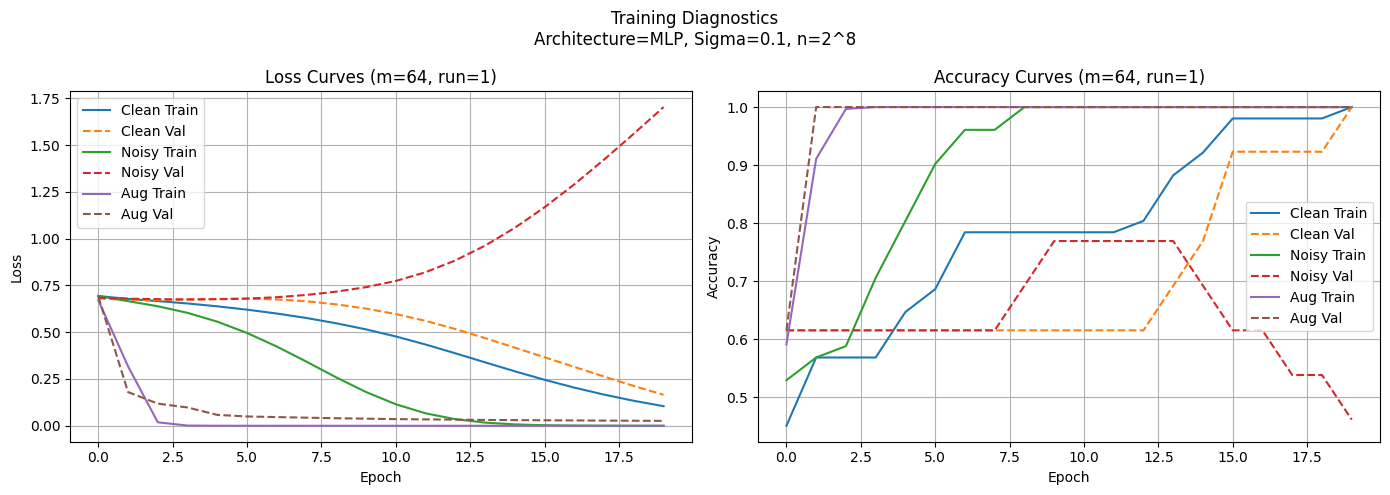

m=64 | clean=1.000, noisy=0.769, aug=1.000

--- n=SINGLE, m=128 ---


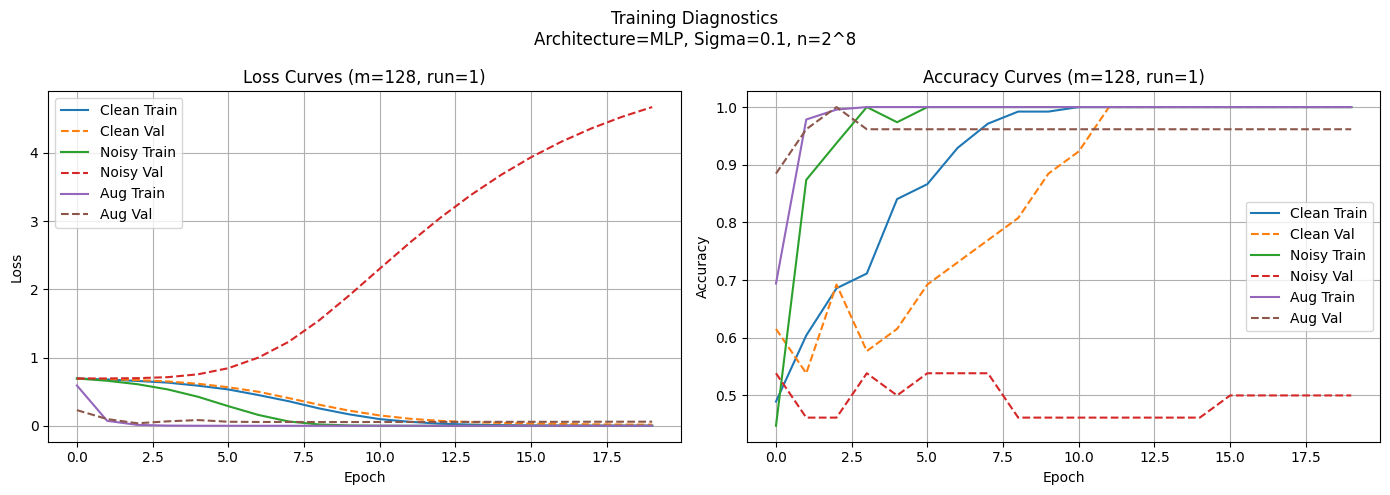

m=128 | clean=1.000, noisy=0.538, aug=1.000

--- n=SINGLE, m=256 ---


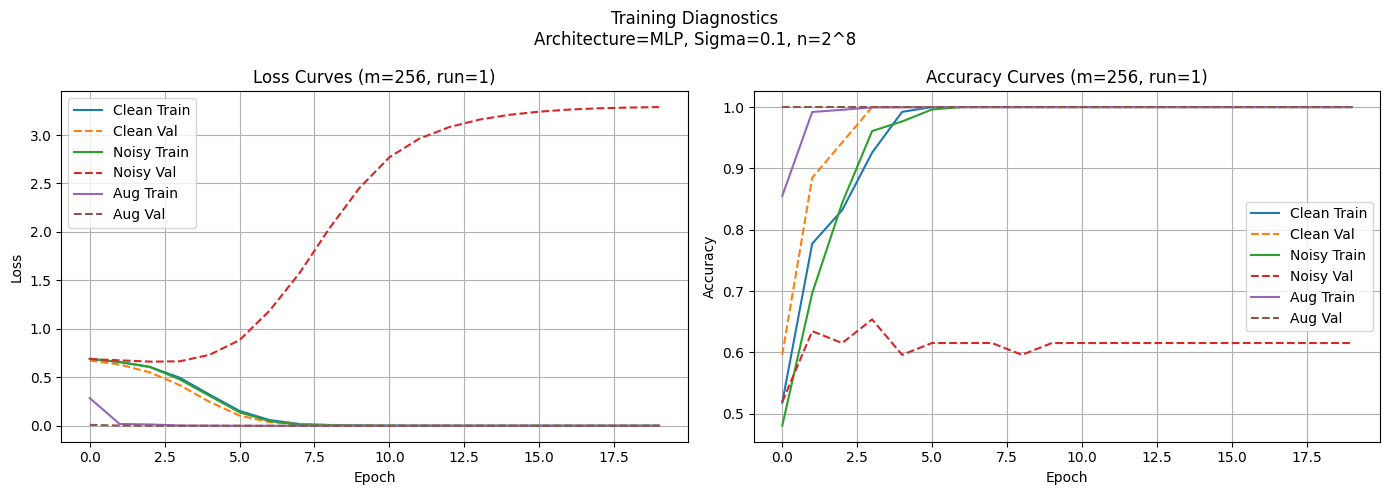

m=256 | clean=1.000, noisy=0.654, aug=1.000

--- n=SINGLE, m=512 ---


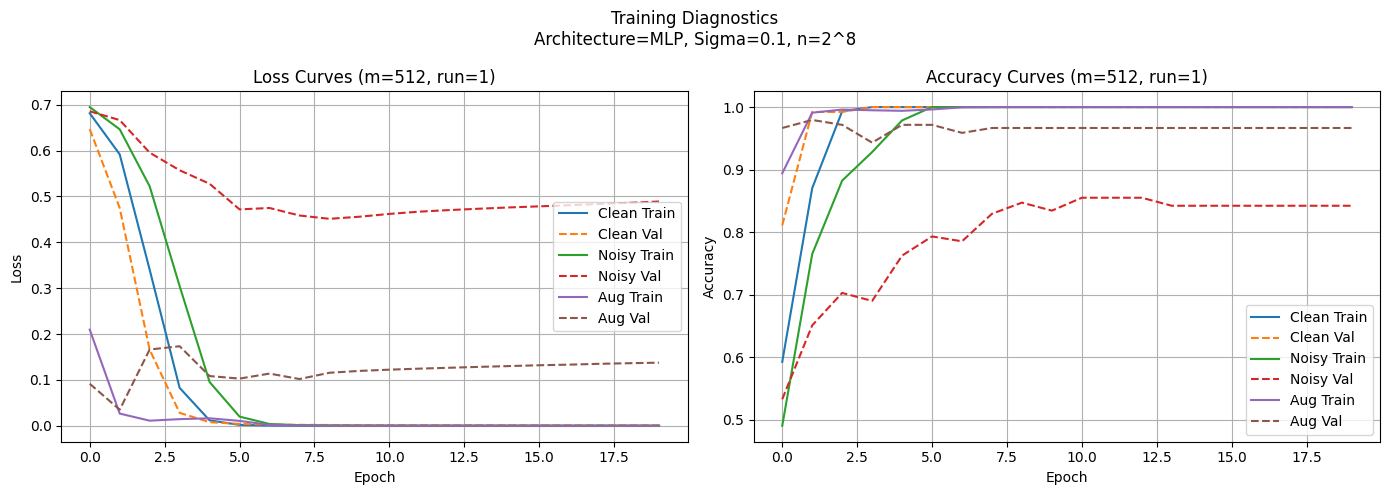

m=512 | clean=1.000, noisy=0.855, aug=0.979


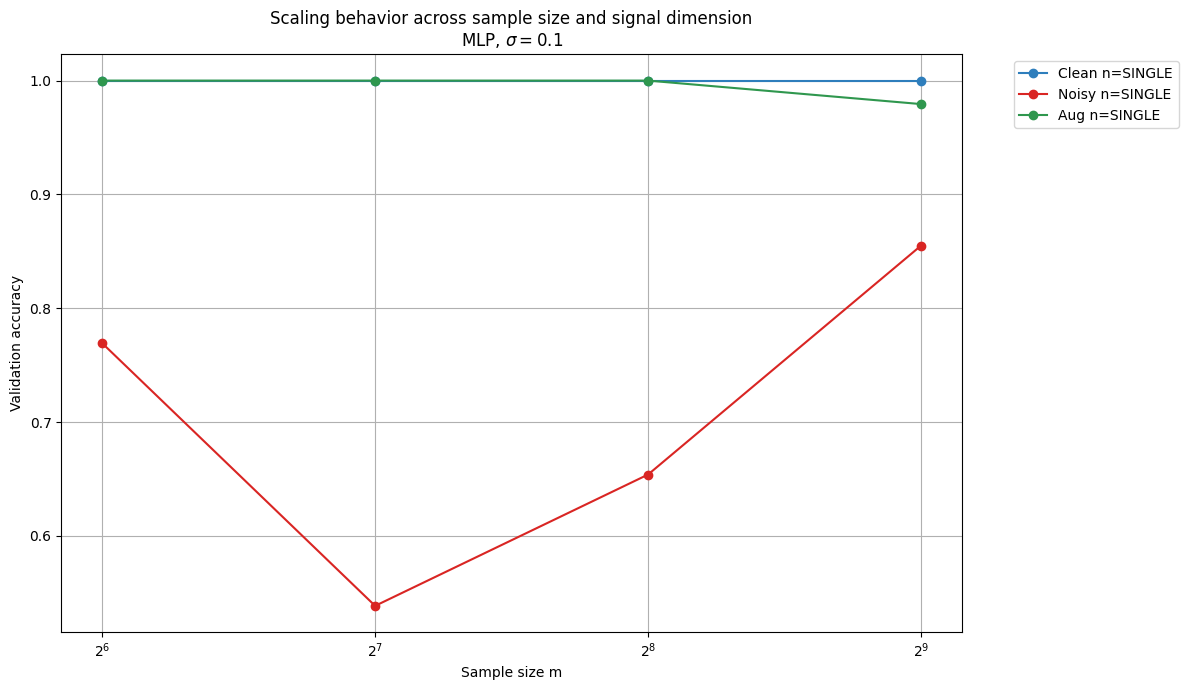

In [ ]:
results = run_experiment(
    load_dataset=lambda: load_dataset(0),
    build_dataloaders=build_dataloaders,
    arch="MLP",
    N_VALUES=None,
    M_VALUES=M_VALUES,
    sigma=SIGMA,
    r=R,
    n_runs=N_RUNS,
    device=DEVICE,
    max_epochs=MAX_EPOCHS,
    arch_configs=ARCH_CONFIGS,
)

## Architecture CNN


Running experiments for n=8

--- n=8, m=64 ---


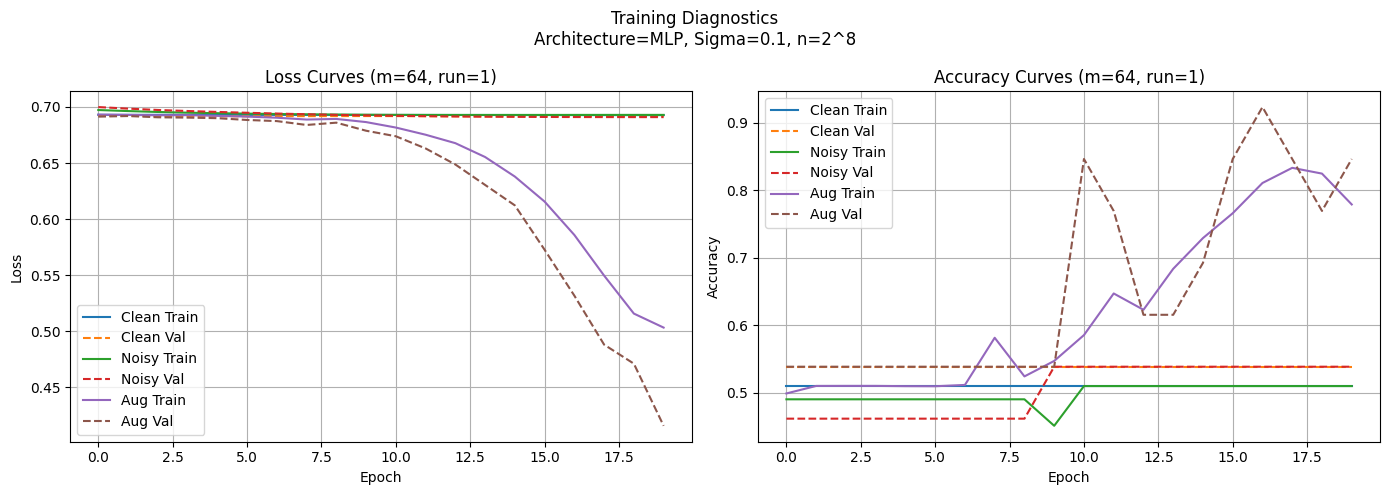

m=64 | clean=0.538, noisy=0.538, aug=0.923

--- n=8, m=128 ---


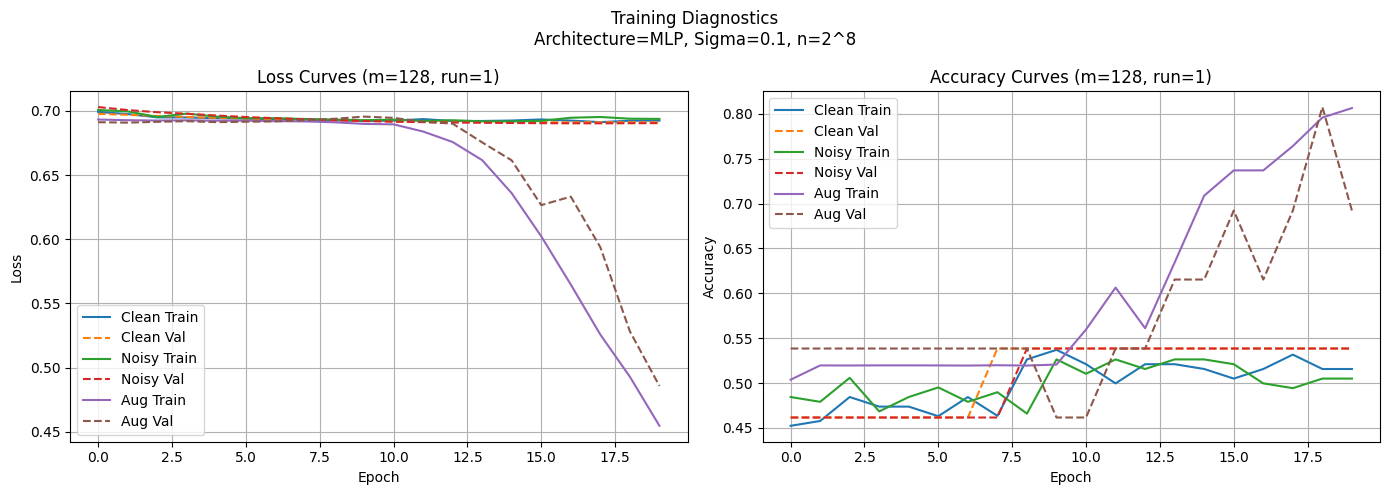

m=128 | clean=0.538, noisy=0.538, aug=0.808

--- n=8, m=256 ---


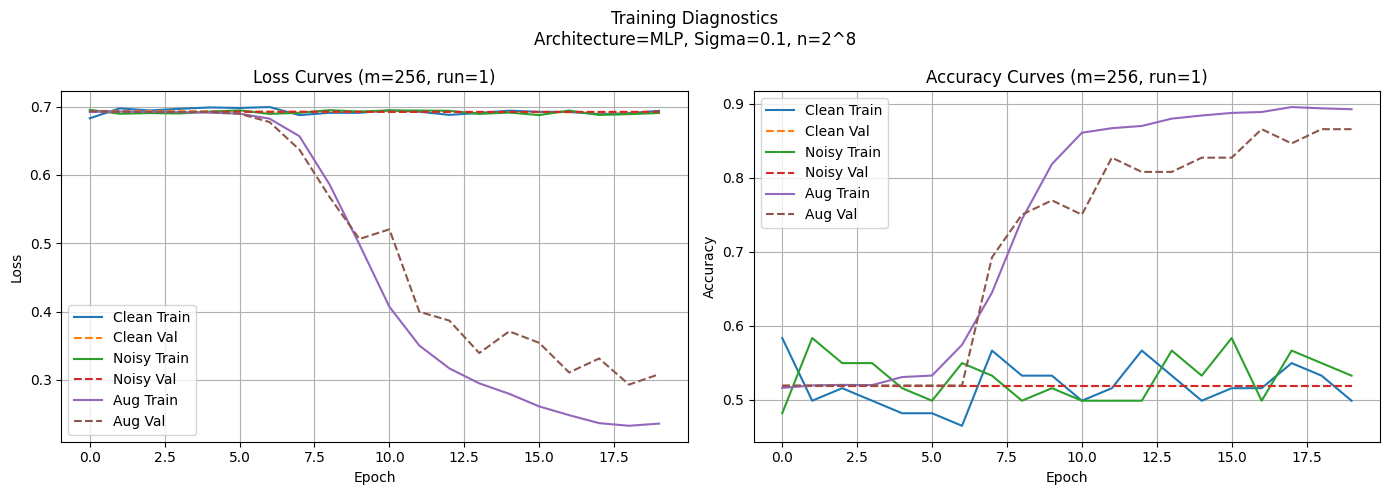

m=256 | clean=0.519, noisy=0.519, aug=0.865

--- n=8, m=512 ---


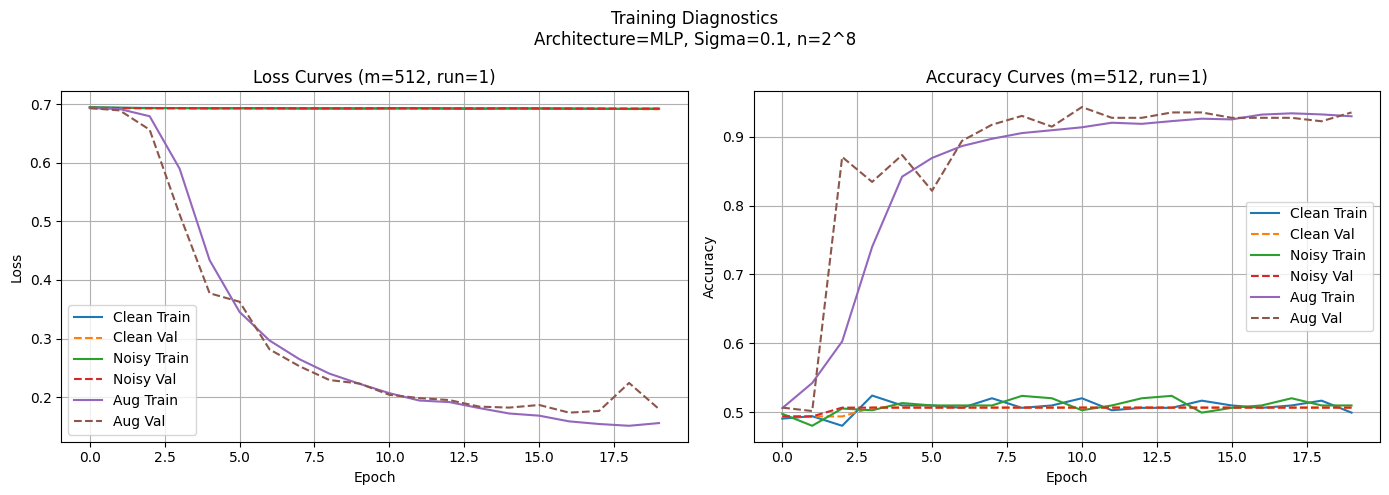

m=512 | clean=0.506, noisy=0.506, aug=0.943


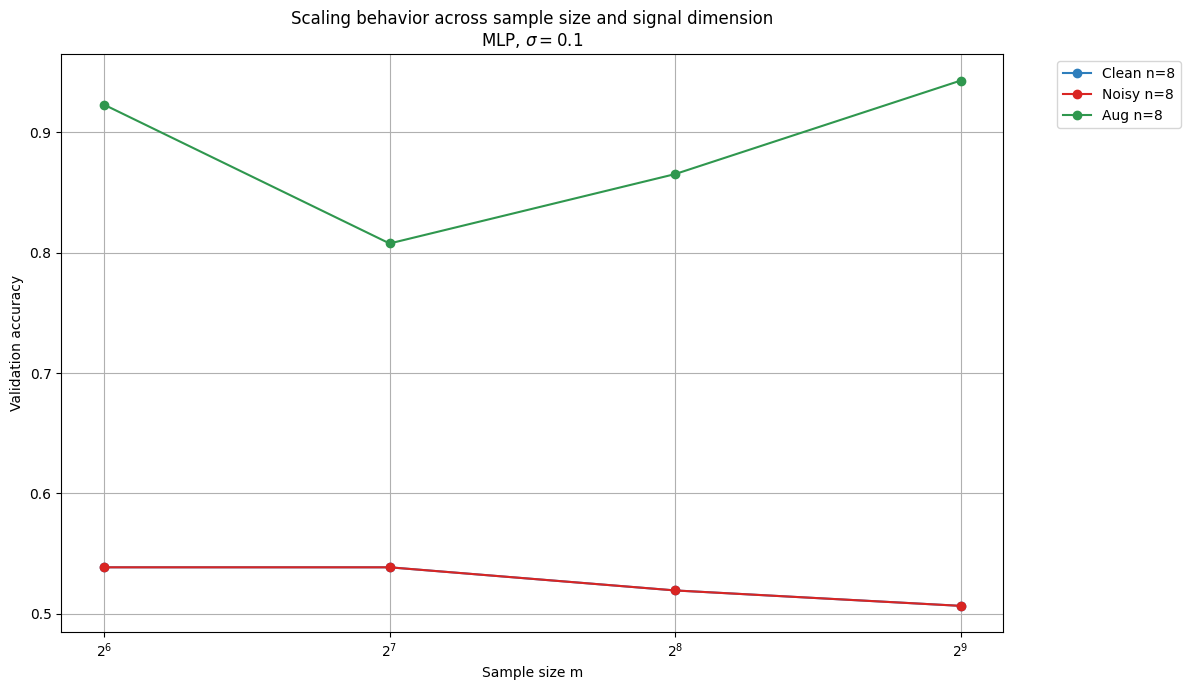

In [ ]:
# results = run_experiment(
#     load_dataset=lambda n: load_dataset(n),
#     build_dataloaders=build_dataloaders,
#     arch="CNN",
#     N_VALUES=list(range(8, 9)),
#     M_VALUES=M_VALUES,
#     sigma=SIGMA,
#     r=R,
#     n_runs=N_RUNS,
#     device=DEVICE,
#     max_epochs=MAX_EPOCHS,
#     arch_configs=ARCH_CONFIGS,
# )

# TODOs
- impl master function x
- fix master function: stopping criterion should be based on val loss
- make sure that in small sample regime at least one positive and negative is included
- improve CNN arch so that it doesnt train as long
- data generation for multiple n